# Phase 2 · 16단원 — 이상 탐지

> "정상은 정의하기 쉽습니다. 비정상은 거기에 안 맞는 전부입니다."
> (📗 원문의 여는 문장입니다.)

- 원문: <https://aiengineeringfromscratch.com/lesson?path=phases/02-ml-fundamentals/16-anomaly-detection>
- 예상 시간: 75분 · 선수 지식: Phase 2의 1~9단원

---

## 📌 출처 표시 규칙

> 📗 **원문** — 커리큘럼에 있는 내용입니다.

> ✨ **추가** — 원문에는 없고, 제가 넣은 비유·예시·실험입니다.

> ⚠️ 표시가 붙은 곳은 원문의 주장이 측정과 달랐던 곳입니다. 그대로 적었습니다.

---

## 🎯 이 단원에서 배우는 것

> 📗 **원문** — "Learning Objectives"

1. Z-score, IQR, Isolation Forest 를 **밑바닥부터** 만듭니다.
2. 점·맥락·집단 이상치를 구분하고, 각각에 맞는 방법을 고릅니다.
3. 이상 탐지가 왜 "이상치를 분류"가 아니라 **"정상을 모델링"** 인지 설명합니다.
4. 비지도 탐지와 지도 분류를 비교합니다. 새로운 유형을 잡는 대신 정밀도를 잃는 맞바꿈입니다.

### 🔑 이 단원의 핵심 한 줄

> 📗 원문: "Anomaly detection flips the problem. Instead of learning what is abnormal,
> learn what is normal. Anything that deviates from normal is suspicious."
>
> (이상 탐지는 문제를 뒤집습니다. 비정상을 배우는 대신 정상을 배웁니다.
> 정상에서 벗어난 건 전부 의심스럽습니다.)

왜 뒤집나요? **이상치 레이블이 없기 때문**입니다. 사기는 거래의 0.1%고, 설비 고장은 1년에 몇 번입니다.
3단원 로지스틱 회귀에 "사기" 샘플 열 개를 주고 학습시킬 수는 없습니다.
그리고 레이블이 있어도 소용이 적습니다. 내일의 사기 수법은 오늘과 다르니까요.

---

## 📖 목차

| 절 | 내용 | 출처 |
| --- | --- | --- |
| 1 | 이상치 세 종류: 점 · 맥락 · 집단 | 📗 원문 |
| 2 | 왜 비지도인가 — 세 가지 상황 | 📗 원문 |
| 3 | 🔨 Z-score 직접 만들기 | 📗 원문 |
| 4 | ⚠️ Z-score 가 무너지는 두 지점 (다봉분포 · 오염된 훈련 데이터) | 📗 원문 + ✨ 측정 |
| 5 | 🔨 IQR 직접 만들기 — 더 튼튼한 대안 | 📗 원문 |
| 6 | ⚠️ 단변량의 한계: 각 특징은 정상인데 조합이 이상 | 📗 연습문제 2번 |
| 7 | 🔑 🔨 Isolation Forest 밑바닥부터 (+ sklearn 대조) | 📗 원문 |
| 8 | LOF — 이웃과 밀도를 비교 | 📗 원문 |
| 9 | ⚠️ 네 방법 정면 비교 — 원문 표가 맞나 | 📗 원문 + ✨ 측정 |
| 10 | 🔑 평가가 어려운 이유 (정확도·AUROC 가 거짓말하는 지점) | 📗 원문 |
| 11 | ⚠️ 임곗값 고르기 — 비용으로 정합니다 | 📗 Ship It |
| 12 | ⚠️ 앙상블이 정말 나은가 | 📗 원문 + ✨ 반증 |
| 13 | 속도 비교와 `contamination` 의 정체 | 📗 원문 + ✨ 측정 |
| 14 | 정리 · Ship It 스킬 · 용어 · 퀴즈 | 📗 원문 `outputs/` · `quiz.json` |

### 🗺️ 이 단원은 이렇게 이어집니다

목차가 길어 보이지만 **하나의 질문**을 따라갑니다.
"레이블 없이 '이상한 것'을 어떻게 찾나?"

- **1절**에서 "이상치"가 한 종류가 아니라는 걸 봅니다. 종류마다 필요한 방법이 다릅니다.
- **2절**에서 왜 지도학습을 못 쓰는지 정리합니다. 여기서 "정상을 모델링한다"는 전략이 나옵니다.
- 가장 단순한 모델링은 "평균에서 얼마나 떨어졌나"입니다. 그게 **3절**의 Z-score 입니다.
- 그런데 Z-score 가 두 군데서 무너집니다. **4절**에서 직접 깨뜨려 봅니다.
- 무너지는 이유 하나가 "평균과 표준편차가 이상치에 끌려간다"입니다. 그래서 **5절**에서 분위수를 쓰는 IQR 로 갑니다.
- IQR 도 못 잡는 게 있습니다. **6절**에서 '각 특징은 정상인데 조합이 이상한' 경우를 만듭니다. 단변량 방법의 공통 한계입니다.
- 그래서 **7절**에서 여러 특징을 같이 보는 Isolation Forest 로 넘어갑니다. 이 단원의 주인공입니다.
- Isolation Forest 도 약점이 있습니다. 밀도가 다른 군집입니다. **8절**의 LOF 가 그걸 노립니다.
- **9절**에서 네 방법을 같은 데이터에 올려 정면 비교합니다. 원문 표와 다른 결과가 나옵니다.
- 비교하려면 점수가 필요한데, 여기서 문제가 생깁니다. **10절**: 불균형이 심하면 정확도도 AUROC도 거짓말을 합니다.
- 점수를 정했으면 **11절**에서 임곗값을 정합니다. 이건 기술이 아니라 비용 계산입니다.
- **12절**에서 "여러 방법을 합치면 낫다"는 통념을 재 봅니다. 결과가 의외입니다.
- **13절**은 실무에서 바로 걸리는 것들입니다. 속도와 `contamination` 파라미터.

한 문장으로 꿰면 이렇습니다.
**단순한 것부터 만들어 깨뜨리고(3~6절) → 더 센 방법으로 옮겨 가며(7~8절) →
정직하게 비교하고(9~10절) → 임곗값과 운영을 정합니다(11~13절).**

---

## 🧭 길잡이 — 이 단원을 왜 배우나

### 지금 어디쯤 와 있나

1단원부터 13단원까지는 **"어떤 모델이 더 좋은가"** 를 배웠습니다.
선형이냐 트리냐, 규제를 얼마나 걸 것이냐 같은 이야기였죠.

14단원부터는 질문이 바뀝니다.
**"지금까지 당연하게 쓰던 기본값이 통하지 않는 상황"** 을 하나씩 보게 됩니다.
네 단원이 한 묶음이에요.

**14단원**은 텍스트입니다. 특징이 수만 개인데 샘플은 적죠. 여기서 "정교한 모델일수록 낫다"는
감각이 깨집니다. 세기만 하는 단순한 모델이 이기거든요.

**15단원**은 시간이 붙은 데이터입니다. 샘플이 서로 독립이 아니라서, 9단원에서 배운
k-겹 교차검증을 쓸 수가 없습니다.

**16단원과 17단원**은 찾는 대상이 아주 드문 경우입니다. 레이블이 없으면 16단원(이상 탐지),
있으면 17단원(불균형 데이터)이고, 둘 다 정확도와 기본 임곗값 0.5 를 버리는 데서 출발합니다.

그래서 이 네 단원은 한마디로 **기본값을 의심하는 연습**입니다.
절 제목에 ⚠️ 가 붙은 곳이 바로 그 기본값이 깨지는 지점이에요.
시간이 없으시면 거기부터 보셔도 됩니다.

> 🧭 **지금 보시는 16단원**은 찾는 대상이 아주 드물고 **레이블이 없는** 경우입니다. 정답이 없으니 "정상을 모델링하고 벗어난 걸 표시한다"로 방향을 틉니다.


### 이 단원이 끝나면 할 수 있는 것

레이블 없이 이상한 걸 찾아야 할 때 **어떤 탐지기부터 볼지** 정할 수 있게 됩니다.
"AUROC 0.95인데 현장에서는 안 잡힌다"는 상황을 설명하고 미리 막을 수 있게 되고요.
알람을 하루 몇 건 울릴지를 감이 아니라 **비용으로 계산**하게 됩니다.
그리고 탐지기를 여러 개 섞을 때 하면 안 되는 방식을 알게 됩니다.

### 실험을 따라가는 순서

**1절**은 이상치가 한 종류가 아니라는 데서 시작합니다.
`3 을 넘나?` 열을 보면 점 이상치만 '예'입니다.
그런데 바로 아래에서 계절을 빼고 다시 재면 잡힙니다.
못 잡은 게 **방법 탓이 아니라 특징 탓**이었다는 뜻이죠.

**2절**은 지도와 비지도의 맞바꿈입니다. `유형B 재현율` 열만 보세요.
지도 모델은 10%, 비지도는 100% 입니다. 훈련에 없던 유형은 비지도만 잡습니다.

**3절**에서 가장 단순한 Z-score 를 만듭니다. 그리고 4절에서 바로 깨뜨립니다.

**4절**은 두 군데서 깨뜨립니다.
군집이 여럿인 데이터에서 `P@20 = 0.000` — 한 개도 못 잡습니다.
그리고 오염 표의 `탐지율` 열이 100%에서 0%로 떨어집니다.
**이상치가 많을수록 더 못 잡는** 역설이에요.

**5절**에서 IQR 로 옮깁니다. 같은 오염 표에서 `IQR 탐지율` 이 **100% 를 유지**하는 걸 보세요.
분위수는 극단값에 안 끌려갑니다.

**6절**은 Z-score 와 IQR 의 공통 약점입니다.
둘 다 `P@20 = 0.000` 인데 LOF 는 0.800 입니다.
특징을 하나씩 따로 보면 **조합** 이상치를 못 봅니다.

**7절**이 이 단원의 주인공입니다.
경로 길이 `정상 13.153` vs `이상 4.570` 만 보면 원리가 끝납니다.
이상치가 2.9배 빨리 고립된다는 것, 그게 점수의 전부예요.

**8절**은 LOF 입니다. 첫 실험에서는 LOF 가 1등을 **못 합니다.**
그래서 다음 셀에서 LOF 가 정말 유리한 상황을 따로 만들어 봅니다.
'전체로는 안 먼데 자기 동네 기준으로만 성긴' 점이어야 하죠.

**9절**에서 네 방법을 다섯 상황에 다 올립니다. `승자` 열만 세로로 훑어보세요.
**상황마다 1등이 바뀝니다.** 만능이 없다는 게 결론입니다.

**10절**이 실무에서 가장 중요한 절입니다. 이동량 1.2 행을 보세요.
AUROC **0.9120** 인데 AUPRC 는 **0.0836** 이고, 상위 50개를 다 봐도 이상치의 20% 밖에 못 잡습니다.
보고서에는 훌륭해 보이는 숫자가 현장에서는 80%를 놓치는 거죠.

**11절**은 임곗값입니다. 잘 분리된 데이터에서는 비용 비율을 100:1 에서 1:3 까지 바꿔도
답이 **2.57% 로 똑같습니다.** 그래서 겹치는 데이터를 하나 더 만들었고,
거기서는 1.83% 와 12.62% 로 갈립니다.
비용이 임곗값을 정하는 건 맞는데 **정밀도와 재현율이 실제로 맞바꿈일 때만** 그렇다는 뜻입니다.

**12절**은 통념을 깹니다. `앙상블 순위` 열과 `5개 상황 평균` 행을 보세요.
평균을 내면 **약한 탐지기에 끌려갑니다.**

**13절**은 실무에서 바로 걸리는 두 가지입니다.
`점수 최대 차이 = 0.00e+00` 한 줄로 `contamination` 이 모델을 안 바꾼다는 걸 확인하고,
속도 표에서 LOF 가 제곱으로 느려지는 걸 봅니다.

### 한 문장으로 꿰면

정확도와 AUROC 대신 **P@k 와 AUPRC** 를 쓰고,
임곗값은 모델이 아니라 **비용**이 정하게 하고,
탐지기 점수를 **평균 내지 마세요.**

---

## ⚙️ 0. 준비

폰트를 먼저 잡습니다. `DejaVu Sans` 를 앞에 두는 게 중요합니다.
안 그러면 그래프의 음수 기호(−)가 두부(□)로 나옵니다.

In [1]:
import warnings
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.font_manager import findfont, FontProperties

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)

후보들 = ["AppleGothic", "Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic"]
찾은것 = None
for 후보 in 후보들:
    try:
        if 후보.lower().replace(" ", "") in findfont(FontProperties(family=후보)).lower().replace(" ", ""):
            찾은것 = 후보
            break
    except Exception:
        pass
matplotlib.rcParams["font.family"] = ["DejaVu Sans"] + ([찾은것] if 찾은것 else [])
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110

난수 = np.random.default_rng(7)
print("준비 끝!  한글 폰트:", 찾은것 or "(없음 — 한글이 □ 로 보일 수 있습니다)")

준비 끝!  한글 폰트: AppleGothic


---

## 1. 이상치 세 종류

> 📗 **원문** — "Types of Anomalies"

### 🧸 먼저 비유

학교에서 "이상한 일"을 찾는다고 해 보세요. 세 가지가 다릅니다.

| 종류 | 학교 비유 | 📗 원문의 예 |
| --- | --- | --- |
| **점 이상치** | 키가 3미터인 학생 | 온도 500도, 평소 5만원 쓰던 계좌의 5천만원 결제 |
| **맥락 이상치** | 7월에 패딩을 입은 학생 | 겨울의 90°F. **같은 값인데 맥락이 다릅니다** |
| **집단 이상치** | 한 명 지각은 정상, 반 전체가 같은 날 지각 | 로그인 실패 5번은 정상, **연속 50번은 무차별 대입 공격** |

### 🔑 왜 구분이 중요한가

> 📗 원문: "Most methods detect point anomalies. Contextual anomalies need time or
> location features. Collective anomalies need sequence-aware methods."

이 단원에서 배울 방법들은 **거의 전부 점 이상치용**입니다.
맥락 이상치를 잡으려면 시간·위치를 특징으로 넣어야 합니다 (15단원의 달력 특징).
집단 이상치를 잡으려면 창(window) 단위 특징이 필요합니다 (15단원의 롤링 통계).

> 즉 "이 방법이 맥락 이상치를 못 잡는다"가 아니라
> "맥락을 특징으로 안 넣으면 어떤 방법도 못 잡는다" 입니다. 문제는 특징 쪽에 있습니다.

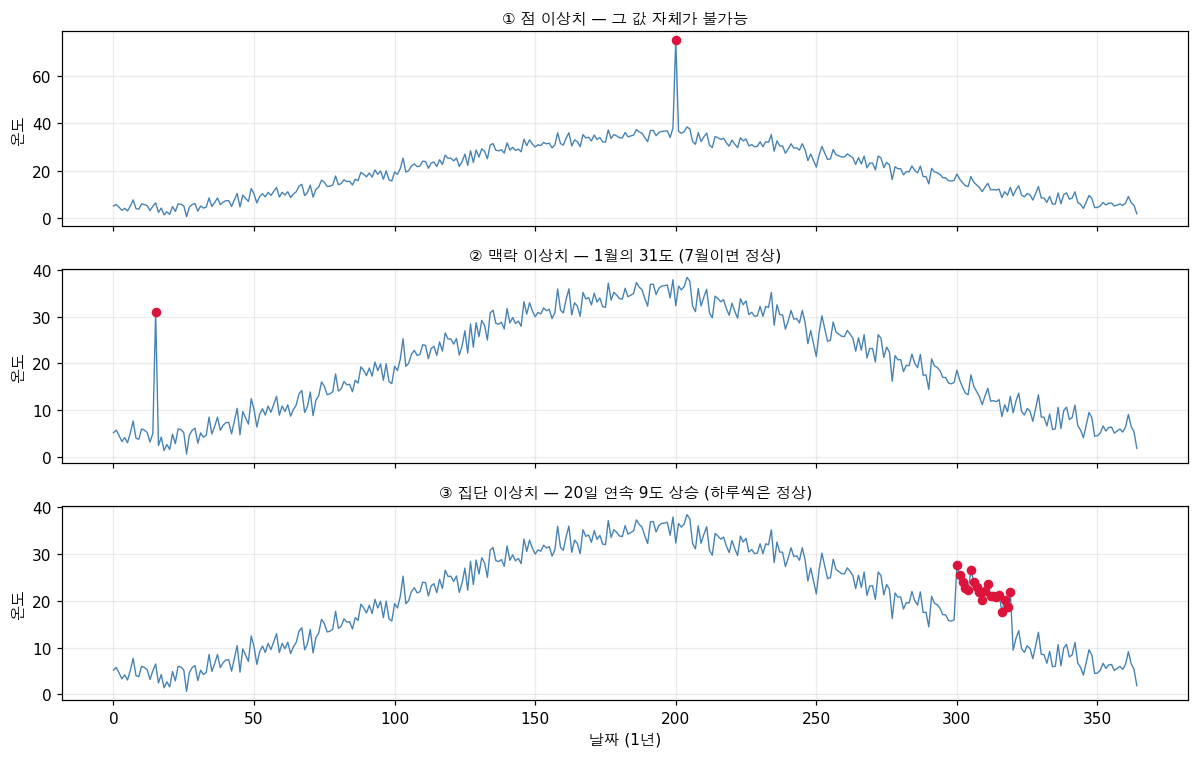

종류                    이상치의 Z-score     3 을 넘나?  결과
--------------------------------------------------------------
점 이상치                        4.966           예  잡힙니다
맥락 이상치                       1.038         아니오  못 잡습니다
집단 이상치                       0.163         아니오  못 잡습니다

=> 점 이상치만 잡힙니다. 나머지 둘은 Z-score 로 안 보입니다.
   · 맥락 이상치: 31도는 1년 전체로 보면 흔한 값입니다. 여름에 널렸으니까요
   · 집단 이상치: 하루하루는 평범합니다. '연속'이라는 게 정보인데 Z-score 는 순서를 안 봅니다

   💡 맥락(계절)을 빼고 다시 재면 Z-score = 11.393 입니다. 이제 잡힙니다.
      방법을 바꾼 게 아니라 특징을 바꿨습니다. 2단원 15단원에서 쓴 그 수법입니다.


In [2]:
# ✨ 추가 — 세 종류를 한 그림에 만들어 봅니다
시간 = np.arange(365)
계절 = 20 + 15 * np.sin(2*np.pi*(시간-100)/365)       # 여름에 덥고 겨울에 춥습니다
온도 = 계절 + 난수.normal(0, 2.0, 365)

점이상 = 온도.copy(); 점이상[200] = 75                  # 7월에 75도 — 아무 때나 불가능
맥락이상 = 온도.copy(); 맥락이상[15] = 31                # 1월에 31도 — 7월이면 정상
집단이상 = 온도.copy(); 집단이상[300:320] += 9           # 20일 연속 9도 높음 — 하루씩은 정상

fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for a_, (라벨, 값, 표시) in zip(ax, [
        ("① 점 이상치 — 그 값 자체가 불가능", 점이상, [200]),
        ("② 맥락 이상치 — 1월의 31도 (7월이면 정상)", 맥락이상, [15]),
        ("③ 집단 이상치 — 20일 연속 9도 상승 (하루씩은 정상)", 집단이상, list(range(300, 320)))]):
    a_.plot(시간, 값, lw=0.9, color="steelblue")
    a_.scatter(표시, 값[표시], color="crimson", s=28, zorder=5)
    a_.set_title(라벨, fontsize=10); a_.set_ylabel("온도"); a_.grid(alpha=0.25)
ax[-1].set_xlabel("날짜 (1년)")
plt.tight_layout(); plt.show()

# Z-score 로 세 가지를 각각 잡아 봅니다
def z점수(v):
    return np.abs((v - v.mean()) / v.std())

print(f"{'종류':<16}{'이상치의 Z-score':>18}{'3 을 넘나?':>12}  결과")
print("-" * 62)
for 라벨, 값, 위치 in [("점 이상치", 점이상, 200), ("맥락 이상치", 맥락이상, 15),
                   ("집단 이상치", 집단이상, 310)]:
    z = z점수(값)[위치]
    print(f"{라벨:<16}{z:>18.3f}{'예' if z > 3 else '아니오':>12}  "
          f"{'잡힙니다' if z > 3 else '못 잡습니다'}")

print("\n=> 점 이상치만 잡힙니다. 나머지 둘은 Z-score 로 안 보입니다.")
print("   · 맥락 이상치: 31도는 1년 전체로 보면 흔한 값입니다. 여름에 널렸으니까요")
print("   · 집단 이상치: 하루하루는 평범합니다. '연속'이라는 게 정보인데 Z-score 는 순서를 안 봅니다")

# 맥락을 특징으로 넣으면 어떻게 되나
잔차 = 맥락이상 - 계절                                  # 계절을 빼면 '맥락 보정'이 됩니다
z보정 = np.abs((잔차 - 잔차.mean()) / 잔차.std())[15]
print(f"\n   💡 맥락(계절)을 빼고 다시 재면 Z-score = {z보정:.3f} 입니다. 이제 잡힙니다.")
print(f"      방법을 바꾼 게 아니라 특징을 바꿨습니다. 2단원 15단원에서 쓴 그 수법입니다.")

---

## 2. 왜 비지도인가

> 🔗 **앞 절과 이어서** — 1절에서 "뭘 찾을 건가"를 정했습니다.
> 그럼 "어떻게 배울 건가"인데, 여기서 지금까지와 다른 길로 갑니다.

> 📗 **원문** — "The Unsupervised Framing" + "Supervised vs Unsupervised: The Tradeoff"

### 📐 세 가지 상황

| 상황 | 가진 것 | 하는 일 |
| --- | --- | --- |
| **완전 비지도** | 레이블 전혀 없음 | 전체 데이터에 맞추고, 이상치가 드물어서 모델을 망치지 않기를 바랍니다 |
| **준지도** | 깨끗한 정상 데이터만 | 그걸로 학습하고 나머지를 채점합니다. 📗 원문: "the strongest setup when possible" |
| **약지도** | 이상치 레이블 몇 개 | **학습이 아니라 평가에만** 씁니다 |

> "완전 비지도"의 가정이 조금 불안합니다. "이상치가 드물기를 바란다"니까요.
> 4절에서 그 가정이 깨지면 어떻게 되는지 직접 재 봅니다.

### 🔑 지도 vs 비지도 — 맞바꿈

> 📗 원문의 요약입니다.

| | 지도 (분류로 다루기) | 비지도 (정상을 모델링) |
| --- | --- | --- |
| 잡는 것 | **전에 본 유형**을 정확히 | 정상에서 벗어난 **전부** |
| 정밀도 | 높음 | 낮음 (이상하다고 다 나쁜 건 아니니까요) |
| 새 유형 | **전부 놓칩니다** | 잡습니다 |
| 필요한 것 | 이상치 샘플이 충분히 (보통 없습니다) | 없음 |

> 📗 원문의 결론: "the best systems combine both"
> 비지도로 넓게 훑고, 알려진 고위험 유형은 지도 모델로 따로 잡고, 애매한 건 사람이 봅니다.

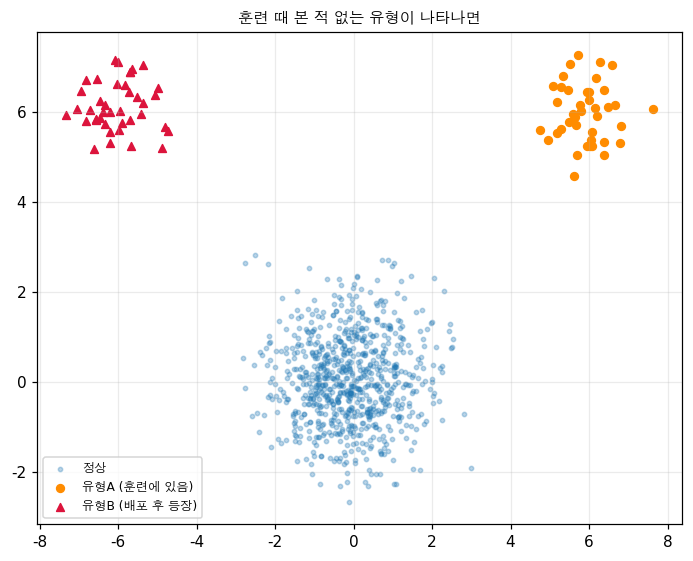

방법                          유형A 재현율       유형B 재현율    전체 AUPRC
--------------------------------------------------------------
지도 (로지스틱)                    100.0%         10.0%       0.548
비지도 (IForest)                100.0%        100.0%       1.000

=> 📗 원문의 맞바꿈이 그대로 재현됩니다.
   · 지도 모델은 유형A 를 완벽하게 잡습니다. 훈련에서 봤으니까요
   · 그런데 유형B 는 거의 못 잡습니다. '사기는 오른쪽 위에 있다'고 배웠는데 왼쪽 위에 나타났으니까요
   · 비지도는 둘 다 잡습니다. '정상에서 멀다'만 보니까 방향을 안 가립니다

   💡 실무에서는 둘 다 씁니다. 지도로 알려진 유형을 정밀하게,
      비지도로 모르는 유형을 넓게 훑습니다. 📗 원문: 'the best systems combine both'


In [3]:
# ✨ 추가 — '지도는 새 유형을 놓친다'를 직접 재 봅니다
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score

정상 = 난수.normal([0, 0], 1.0, (800, 2))
유형A = 난수.normal([6, 6], 0.6, (40, 2))       # 훈련 때 본 사기 유형
유형B = 난수.normal([-6, 6], 0.6, (40, 2))      # 배포 후에 나타난 새 유형

# 훈련: 정상 + 유형A 만 있습니다
X훈련 = np.vstack([정상[:600], 유형A[:20]])
y훈련 = np.r_[np.zeros(600), np.ones(20)]

# 테스트: 정상 + 유형A + 유형B (새 유형!)
X테스트 = np.vstack([정상[600:], 유형A[20:], 유형B])
y테스트 = np.r_[np.zeros(200), np.ones(20), np.ones(40)]
유형표 = np.r_[np.full(200, "정상"), np.full(20, "유형A"), np.full(40, "유형B(새것)")]

지도 = LogisticRegression(max_iter=2000).fit(X훈련, y훈련)
지도점수 = 지도.predict_proba(X테스트)[:, 1]
비지도 = IsolationForest(random_state=0).fit(정상[:600])     # 정상만 보고 학습 (준지도)
비지도점수 = -비지도.score_samples(X테스트)

plt.figure(figsize=(6.4, 5.2))
plt.scatter(*정상.T, s=8, alpha=0.3, label="정상")
plt.scatter(*유형A.T, s=26, color="darkorange", label="유형A (훈련에 있음)")
plt.scatter(*유형B.T, s=26, color="crimson", marker="^", label="유형B (배포 후 등장)")
plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.title("훈련 때 본 적 없는 유형이 나타나면", fontsize=10)
plt.tight_layout(); plt.show()

print(f"{'방법':<22}{'유형A 재현율':>13}{'유형B 재현율':>14}{'전체 AUPRC':>12}")
print("-" * 62)
for 이름, 점수 in [("지도 (로지스틱)", 지도점수), ("비지도 (IForest)", 비지도점수)]:
    상위 = np.argsort(-점수)[:60]                  # 상위 60개를 플래그
    잡은것 = np.zeros(len(y테스트), bool); 잡은것[상위] = True
    재A = 잡은것[유형표 == "유형A"].mean()
    재B = 잡은것[유형표 == "유형B(새것)"].mean()
    print(f"{이름:<22}{재A:>13.1%}{재B:>14.1%}{average_precision_score(y테스트, 점수):>12.3f}")

print("\n=> 📗 원문의 맞바꿈이 그대로 재현됩니다.")
print("   · 지도 모델은 유형A 를 완벽하게 잡습니다. 훈련에서 봤으니까요")
print("   · 그런데 유형B 는 거의 못 잡습니다. '사기는 오른쪽 위에 있다'고 배웠는데 왼쪽 위에 나타났으니까요")
print("   · 비지도는 둘 다 잡습니다. '정상에서 멀다'만 보니까 방향을 안 가립니다")
print("\n   💡 실무에서는 둘 다 씁니다. 지도로 알려진 유형을 정밀하게,")
print("      비지도로 모르는 유형을 넓게 훑습니다. 📗 원문: 'the best systems combine both'")

---

## 3. Z-score 직접 만들기

> 🔗 **앞 절과 이어서** — 2절에서 "정상을 모델링한다"고 정했습니다.
> 가장 단순한 모델은 "정상은 평균 근처에 있다"입니다. 거기서 출발합니다.

> 📗 **원문** — "Z-Score Method"

### 📐 공식은 한 줄입니다

$$z = \frac{x - \mu}{\sigma}, \qquad |z| > \text{임곗값} \Rightarrow \text{이상}$$

기본 임곗값은 **3.0** 입니다. 정규분포라면 데이터의 99.7%가 3 표준편차 안에 들어오니까요.

### 🧸 쉬운 말로

반 평균 키가 160cm 이고 표준편차가 8cm 라면, 184cm 인 학생은 z = 3 입니다.
"평균에서 표준편차 세 개만큼 떨어졌다"는 뜻이죠. 흔치 않습니다.

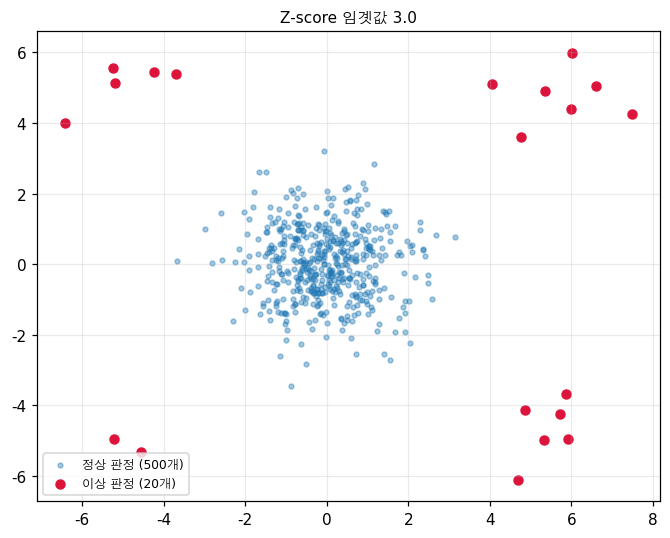

진짜 이상치 20개 중 20개를 잡았습니다 (재현율 100.0%)
정상인데 이상이라고 한 것: 0개 (정밀도 100.0%)

[임곗값을 바꿔 가며 — 📗 연습문제 1번]
    임곗값     플래그 수      정밀도      재현율       F1
----------------------------------------------
    1.0       164    0.122    1.000    0.217
    1.5        55    0.364    1.000    0.533
    2.0        27    0.741    1.000    0.851
    2.5        22    0.909    1.000    0.952
    3.0        20    1.000    1.000    1.000
    3.5        18    1.000    0.900    0.947
    4.0         8    1.000    0.400    0.571
    5.0         1    1.000    0.050    0.095

=> 이 데이터에서는 임곗값을 올려도 재현율이 안 떨어집니다. 이상치가 아주 멀리 있어서죠.
   📗 원문의 기본값 3.0 이 잘 맞는 상황입니다. 4절에서 안 맞는 상황을 봅니다.


In [4]:
# 📗 원문의 zscore_detect 를 그대로 옮깁니다
def Z탐지(X, 임곗값=3.0):
    평균 = X.mean(axis=0)
    표준 = X.std(axis=0)
    표준[표준 == 0] = 1.0                 # 0으로 나누기 방지
    z = np.abs((X - 평균) / 표준)
    return z.max(axis=1) > 임곗값        # 특징 하나라도 넘으면 이상

def Z점수(X):
    평균, 표준 = X.mean(axis=0), X.std(axis=0)
    표준 = np.where(표준 == 0, 1.0, 표준)
    return np.abs((X - 평균) / 표준).max(axis=1)

# 간단한 데이터로 확인
단순정상 = 난수.normal(0, 1, (500, 2))
단순이상 = 난수.normal(0, 1, (20, 2)) + 난수.choice([-1, 1], (20, 2)) * 5
X단순 = np.vstack([단순정상, 단순이상])
y단순 = np.r_[np.zeros(500), np.ones(20)]

점수 = Z점수(X단순)
플래그 = Z탐지(X단순)

plt.figure(figsize=(6.2, 5))
plt.scatter(*X단순[~플래그].T, s=10, alpha=0.4, label=f"정상 판정 ({(~플래그).sum()}개)")
plt.scatter(*X단순[플래그].T, s=34, color="crimson", label=f"이상 판정 ({플래그.sum()}개)")
plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.title("Z-score 임곗값 3.0", fontsize=10)
plt.tight_layout(); plt.show()

진양 = (플래그 & (y단순 == 1)).sum()
위양 = (플래그 & (y단순 == 0)).sum()
print(f"진짜 이상치 {int(y단순.sum())}개 중 {진양}개를 잡았습니다 "
      f"(재현율 {진양/y단순.sum():.1%})")
print(f"정상인데 이상이라고 한 것: {위양}개 "
      f"(정밀도 {진양/max(1,플래그.sum()):.1%})")

print(f"\n[임곗값을 바꿔 가며 — 📗 연습문제 1번]")
print(f"{'임곗값':>7}{'플래그 수':>10}{'정밀도':>9}{'재현율':>9}{'F1':>9}")
print("-" * 46)
for 임 in (1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0):
    f = Z점수(X단순) > 임
    tp = (f & (y단순 == 1)).sum()
    정 = tp / f.sum() if f.sum() else 0.0
    재 = tp / y단순.sum()
    F1 = 2*정*재/(정+재) if (정+재) else 0.0
    print(f"{임:>7.1f}{f.sum():>10}{정:>9.3f}{재:>9.3f}{F1:>9.3f}")

최적 = max([(임, Z점수(X단순) > 임) for 임 in np.arange(1.0, 6.01, 0.1)],
          key=lambda r: (lambda f: (lambda tp: 2*tp/(f.sum()+y단순.sum()) if (f.sum()+y단순.sum()) else 0)
                         ((f & (y단순 == 1)).sum()))(r[1]))
print(f"\n=> 이 데이터에서는 임곗값을 올려도 재현율이 안 떨어집니다. 이상치가 아주 멀리 있어서죠.")
print(f"   📗 원문의 기본값 3.0 이 잘 맞는 상황입니다. 4절에서 안 맞는 상황을 봅니다.")

---

## 4. ⚠️ Z-score 가 무너지는 두 지점

> 🔗 **앞 절과 이어서** — 3절의 데이터는 Z-score 에게 유리했습니다.
> 군집이 하나였고 이상치가 멀리 있었죠. 조건을 바꾸면 어떻게 되는지 봅니다.

> 📗 원문이 지적하는 약점입니다.
>
> - "Assumes data is normally distributed... Fails on multimodal distributions."
> - "Sensitive to outliers in the training data (the outliers shift the mean and inflate the std, making them harder to detect)."

두 가지를 각각 측정합니다.

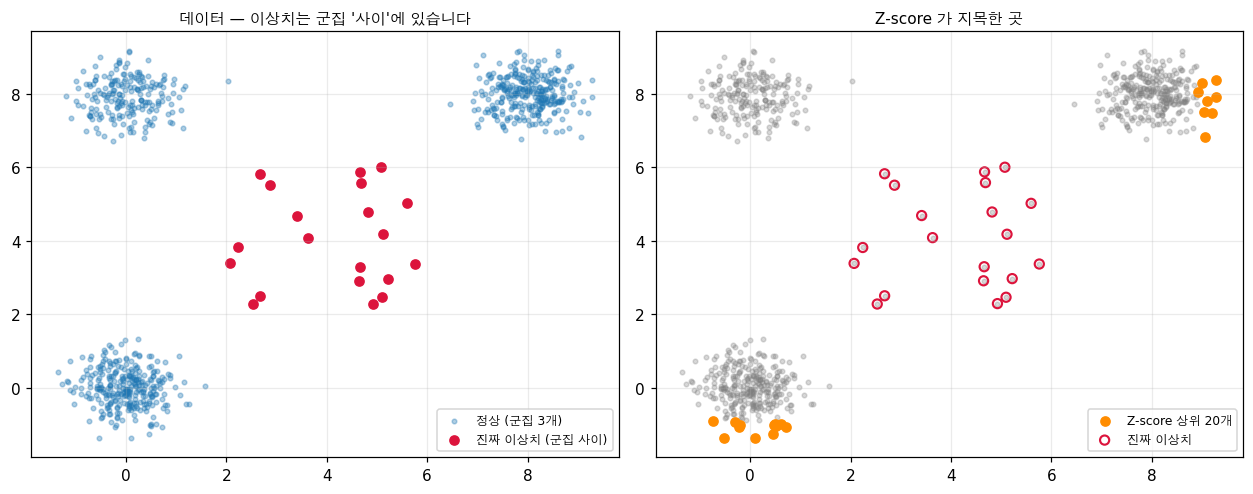

Z-score 상위 20개 중 진짜 이상치: 0개 / 20개 (P@20 = 0.000)

=> ⚠️ 한 개도 못 잡습니다. 왜 그럴까요?
   전체 평균이 (3.03, 4.96) 인데, 그 지점에는 데이터가 하나도 없습니다.
   세 군집의 한가운데거든요. 그리고 거기가 바로 이상치가 있는 자리입니다.
   Z-score 는 '평균에서 멀면 이상'이라고 하니, 평균 근처의 이상치를 가장 정상이라고 판정합니다.

   대신 뭘 지목했나요? 군집들의 바깥 가장자리입니다. 전부 정상인 점이죠.
   📗 원문의 'Fails on multimodal distributions' 가 정확히 이 모습입니다.


In [5]:
# ⚠️ 무너지는 지점 ① — 군집이 여러 개일 때
군집들 = np.vstack([난수.normal([0, 0], 0.5, (300, 2)),
                  난수.normal([8, 8], 0.5, (300, 2)),
                  난수.normal([0, 8], 0.5, (200, 2))])
사이이상 = 난수.uniform([2, 2], [6, 6], (20, 2))     # 군집 '사이'의 빈 공간
X다봉 = np.vstack([군집들, 사이이상])
y다봉 = np.r_[np.zeros(800), np.ones(20)]

z다봉 = Z점수(X다봉)
상위20 = np.argsort(-z다봉)[:20]

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax[0].scatter(*군집들.T, s=9, alpha=0.35, label="정상 (군집 3개)")
ax[0].scatter(*사이이상.T, s=36, color="crimson", label="진짜 이상치 (군집 사이)")
ax[0].set_title("데이터 — 이상치는 군집 '사이'에 있습니다", fontsize=10)
ax[1].scatter(*X다봉.T, s=9, alpha=0.3, c="gray")
ax[1].scatter(*X다봉[상위20].T, s=36, color="darkorange", label="Z-score 상위 20개")
ax[1].scatter(*사이이상.T, s=36, facecolors="none", edgecolors="crimson",
              linewidths=1.4, label="진짜 이상치")
ax[1].set_title("Z-score 가 지목한 곳", fontsize=10)
for a_ in ax:
    a_.legend(fontsize=8); a_.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(f"Z-score 상위 20개 중 진짜 이상치: {int(y다봉[상위20].sum())}개 / 20개 "
      f"(P@20 = {y다봉[상위20].sum()/20:.3f})")
print(f"\n=> ⚠️ 한 개도 못 잡습니다. 왜 그럴까요?")
print(f"   전체 평균이 ({X다봉.mean(0)[0]:.2f}, {X다봉.mean(0)[1]:.2f}) 인데, "
      f"그 지점에는 데이터가 하나도 없습니다.")
print(f"   세 군집의 한가운데거든요. 그리고 거기가 바로 이상치가 있는 자리입니다.")
print(f"   Z-score 는 '평균에서 멀면 이상'이라고 하니, 평균 근처의 이상치를 "
      f"가장 정상이라고 판정합니다.")
print(f"\n   대신 뭘 지목했나요? 군집들의 바깥 가장자리입니다. 전부 정상인 점이죠.")
print(f"   📗 원문의 'Fails on multimodal distributions' 가 정확히 이 모습입니다.")

훈련 데이터에 이상치가 섞여 있을 때, 같은 이상치를 탐지할 수 있나

    오염 비율      훈련 평균       훈련 표준편차       이상치의 평균 z     탐지율(z>3)
------------------------------------------------------------------
       0%      0.056         0.986           9.608       100.0%
       1%      0.158         1.416           6.616       100.0%
       2%      0.252         1.696           5.468       100.0%
       5%      0.524         2.313           3.893       100.0%
      10%      0.963         3.036           2.820        35.0%
      15%      1.341         3.464           2.363         0.0%
      20%      1.716         3.842           2.033         0.0%


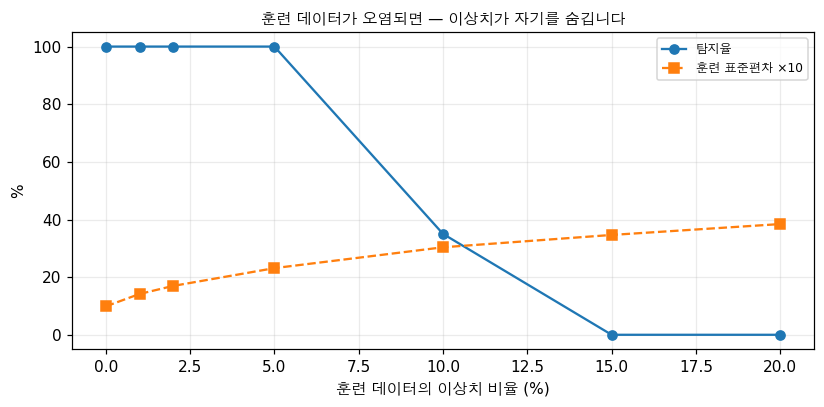


=> 📗 원문의 'outliers shift the mean and inflate the std' 가 확인됩니다.
   오염이 0%면 표준편차가 0.986 인데, 20%면 3.842 로 3.9배 부풀었습니다.
   탐지율이 떨어지기 시작하는 지점: 오염 10%
   완전히 못 잡게 되는 지점: 오염 20% (탐지율 0%)

   ⚠️ 여기에 고약한 함정이 있습니다. 이상치가 많을수록 더 못 잡습니다.
      보통은 데이터가 많으면 좋은데, 이상 탐지에서는 반대입니다.
      이상치가 스스로 '정상의 기준'을 넓혀서 자기를 숨기는 셈이죠.

   💡 그래서 2절의 '준지도'(깨끗한 정상 데이터만으로 학습)가 가장 강합니다.
      그게 불가능하면 평균·표준편차 대신 분위수를 쓰면 됩니다. 5절입니다.


In [6]:
# ⚠️ 무너지는 지점 ② — 훈련 데이터가 오염되면 (2절의 '완전 비지도' 가정)
깨끗한정상 = 난수.normal(0, 1, (500, 1))
시험이상 = 난수.normal(10, 1, (20, 1))            # 평균 10 — 아주 명백한 이상치

print("훈련 데이터에 이상치가 섞여 있을 때, 같은 이상치를 탐지할 수 있나")
print(f"\n{'오염 비율':>9}{'훈련 평균':>11}{'훈련 표준편차':>14}"
      f"{'이상치의 평균 z':>16}{'탐지율(z>3)':>13}")
print("-" * 66)
오염기록 = []
for 오염률 in (0.0, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20):
    n이상 = int(500 * 오염률)
    훈련 = np.vstack([깨끗한정상, 난수.normal(10, 1, (n이상, 1))]) if n이상 else 깨끗한정상
    평균, 표준 = 훈련.mean(), 훈련.std()
    z = np.abs((시험이상 - 평균) / 표준)
    탐지율 = (z > 3).mean()
    오염기록.append((오염률, 평균, 표준, z.mean(), 탐지율))
    print(f"{오염률:>9.0%}{평균:>11.3f}{표준:>14.3f}{z.mean():>16.3f}{탐지율:>13.1%}")

plt.figure(figsize=(7.6, 3.8))
plt.plot([r[0]*100 for r in 오염기록], [r[4]*100 for r in 오염기록], "o-", label="탐지율")
plt.plot([r[0]*100 for r in 오염기록], [r[2]*10 for r in 오염기록], "s--",
         label="훈련 표준편차 ×10")
plt.xlabel("훈련 데이터의 이상치 비율 (%)"); plt.ylabel("%")
plt.title("훈련 데이터가 오염되면 — 이상치가 자기를 숨깁니다", fontsize=10)
plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

깨짐 = [r for r in 오염기록 if r[4] < 1.0]
print(f"\n=> 📗 원문의 'outliers shift the mean and inflate the std' 가 확인됩니다.")
print(f"   오염이 0%면 표준편차가 {오염기록[0][2]:.3f} 인데, "
      f"20%면 {오염기록[-1][2]:.3f} 로 {오염기록[-1][2]/오염기록[0][2]:.1f}배 부풀었습니다.")
if 깨짐:
    print(f"   탐지율이 떨어지기 시작하는 지점: 오염 {깨짐[0][0]:.0%}")
    print(f"   완전히 못 잡게 되는 지점: 오염 {오염기록[-1][0]:.0%} (탐지율 {오염기록[-1][4]:.0%})")
print(f"\n   ⚠️ 여기에 고약한 함정이 있습니다. 이상치가 많을수록 더 못 잡습니다.")
print(f"      보통은 데이터가 많으면 좋은데, 이상 탐지에서는 반대입니다.")
print(f"      이상치가 스스로 '정상의 기준'을 넓혀서 자기를 숨기는 셈이죠.")
print(f"\n   💡 그래서 2절의 '준지도'(깨끗한 정상 데이터만으로 학습)가 가장 강합니다.")
print(f"      그게 불가능하면 평균·표준편차 대신 분위수를 쓰면 됩니다. 5절입니다.")

---

## 5. IQR 직접 만들기

> 🔗 **앞 절과 이어서** — 4절의 두 번째 문제(오염)는 "평균과 표준편차가 이상치에 끌려간다"였습니다.
> 끌려가지 않는 통계량을 쓰면 됩니다. 분위수입니다.

> 📗 **원문** — "IQR Method"

### 📐 공식

$$Q_1 = \text{25\% 지점}, \quad Q_3 = \text{75\% 지점}, \quad \text{IQR} = Q_3 - Q_1$$
$$x < Q_1 - k \cdot \text{IQR} \ \text{ 또는 } \ x > Q_3 + k \cdot \text{IQR} \Rightarrow \text{이상}$$

기본 계수 $k$ 는 **1.5** 입니다.

### 🧸 왜 안 끌려가나

반에 키 3미터인 학생이 한 명 들어오면 평균은 올라갑니다.
그런데 중앙값(50% 지점)은 거의 안 움직입니다. 순서상 한 칸 밀릴 뿐이죠.
$Q_1$, $Q_3$ 도 마찬가지입니다. 극단값의 **크기**가 아니라 **순위**만 쓰니까요.

> 📗 원문: "The 1.5 factor in IQR corresponds to the whiskers in a box plot."
> 상자 그림의 수염이 정확히 이 경계입니다.

In [7]:
# 📗 원문의 iqr_detect 를 그대로 옮깁니다
def IQR탐지(X, 계수=1.5):
    q1 = np.percentile(X, 25, axis=0)
    q3 = np.percentile(X, 75, axis=0)
    iqr = q3 - q1
    iqr[iqr == 0] = 1.0
    아래, 위 = q1 - 계수*iqr, q3 + 계수*iqr
    벗어남 = (X < 아래) | (X > 위)
    return 벗어남.any(axis=1)

def IQR점수(X, 계수=1.5):
    # 경계를 얼마나 넘었는지를 점수로 (순위를 매기려면 연속값이 필요합니다)
    q1, q3 = np.percentile(X, 25, axis=0), np.percentile(X, 75, axis=0)
    iqr = np.where(q3 - q1 == 0, 1.0, q3 - q1)
    아래, 위 = q1 - 계수*iqr, q3 + 계수*iqr
    return np.maximum(아래 - X, X - 위).max(axis=1)

# 4절 ②번 실험을 IQR 로 다시
print("4절의 오염 실험을 IQR 로 반복합니다\n")
print(f"{'오염 비율':>9}{'Z-score 탐지율':>16}{'IQR 탐지율':>13}{'Z 표준편차':>12}{'IQR 폭':>10}")
print("-" * 62)
for 오염률 in (0.0, 0.05, 0.10, 0.15, 0.20):
    n이상 = int(500 * 오염률)
    훈련 = np.vstack([깨끗한정상, 난수.normal(10, 1, (n이상, 1))]) if n이상 else 깨끗한정상
    z탐지 = (np.abs((시험이상 - 훈련.mean()) / 훈련.std()) > 3).mean()
    q1, q3 = np.percentile(훈련, 25), np.percentile(훈련, 75)
    iqr = q3 - q1
    i탐지 = ((시험이상 < q1 - 1.5*iqr) | (시험이상 > q3 + 1.5*iqr)).mean()
    print(f"{오염률:>9.0%}{z탐지:>16.1%}{i탐지:>13.1%}{훈련.std():>12.3f}{iqr:>10.3f}")

print("\n=> IQR 은 오염 20% 에서도 전부 잡습니다. Z-score 는 0% 로 떨어졌죠.")
print("   IQR 폭이 거의 안 변하는 걸 보세요. 분위수는 극단값의 크기에 둔감합니다.")
print("   📗 원문: 'Robust to outliers (percentiles are not affected by extreme values)'")

# 계수를 바꿔 가며
print(f"\n[계수를 바꿔 가며 — 📗 원문의 1.5 vs 3.0]")
print(f"{'계수':>6}{'플래그 수':>10}{'정밀도':>9}{'재현율':>9}{'F1':>9}  성격")
print("-" * 58)
for 계수 in (0.5, 1.0, 1.5, 2.0, 3.0, 4.0):
    f = IQR탐지(X단순, 계수)
    tp = (f & (y단순 == 1)).sum()
    정 = tp/f.sum() if f.sum() else 0.0
    재 = tp/y단순.sum()
    F1 = 2*정*재/(정+재) if (정+재) else 0.0
    성격 = "공격적 (오탐 많음)" if 계수 < 1.5 else ("기본값" if 계수 == 1.5 else "보수적 (놓침 많음)")
    print(f"{계수:>6.1f}{f.sum():>10}{정:>9.3f}{재:>9.3f}{F1:>9.3f}  {성격}")

print(f"\n   📗 원문: 'Using 3.0 instead of 1.5 makes the detector more conservative'")
print(f"   확인됩니다. 계수를 올리면 플래그가 줄고 정밀도가 오릅니다.")
print(f"   💡 어느 쪽이 맞는지는 데이터가 아니라 비용이 정합니다. 11절에서 다룹니다.")

4절의 오염 실험을 IQR 로 반복합니다

    오염 비율     Z-score 탐지율      IQR 탐지율      Z 표준편차     IQR 폭
--------------------------------------------------------------
       0%          100.0%       100.0%       0.986     1.320
       5%          100.0%       100.0%       2.311     1.377
      10%           35.0%       100.0%       3.015     1.490
      15%            0.0%       100.0%       3.554     1.626
      20%            0.0%       100.0%       3.822     1.783

=> IQR 은 오염 20% 에서도 전부 잡습니다. Z-score 는 0% 로 떨어졌죠.
   IQR 폭이 거의 안 변하는 걸 보세요. 분위수는 극단값의 크기에 둔감합니다.
   📗 원문: 'Robust to outliers (percentiles are not affected by extreme values)'

[계수를 바꿔 가며 — 📗 원문의 1.5 vs 3.0]
    계수     플래그 수      정밀도      재현율       F1  성격
----------------------------------------------------------
   0.5       151    0.132    1.000    0.234  공격적 (오탐 많음)
   1.0        51    0.392    1.000    0.563  공격적 (오탐 많음)
   1.5        25    0.800    1.000    0.889  기본값
   2.0        21    0.952    1.000    0.976  보수적 (놓침 많음)
   3.0     

---

## 6. ⚠️ 단변량의 한계

> 🔗 **앞 절과 이어서** — IQR 이 Z-score 보다 튼튼했습니다.
> 그런데 둘에게 **공통된** 약점이 하나 있습니다. 둘 다 **특징을 하나씩 따로** 봅니다.

> 📗 원문의 지적입니다.
>
> "Univariate only (applies per feature independently). Cannot detect anomalies that are
> unusual only when features are considered together (a point might be normal in each feature
> individually but anomalous in the joint space)."

📗 **연습문제 2번**이 바로 이걸 만들어 보라고 합니다. 그대로 해 보겠습니다.

각 특징을 '따로' 보면 이상치가 정상 범위 안에 있습니다

                              특징0 범위                특징1 범위
------------------------------------------------------------
정상 전체                 [-2.99, 2.98]         [-3.48, 3.48]
이상치                   [-2.44, 1.93]         [-2.86, 2.58]

=> 이상치의 범위가 정상 범위 안에 완전히 들어가 있습니다.
   특징 하나만 보면 전혀 이상하지 않습니다.


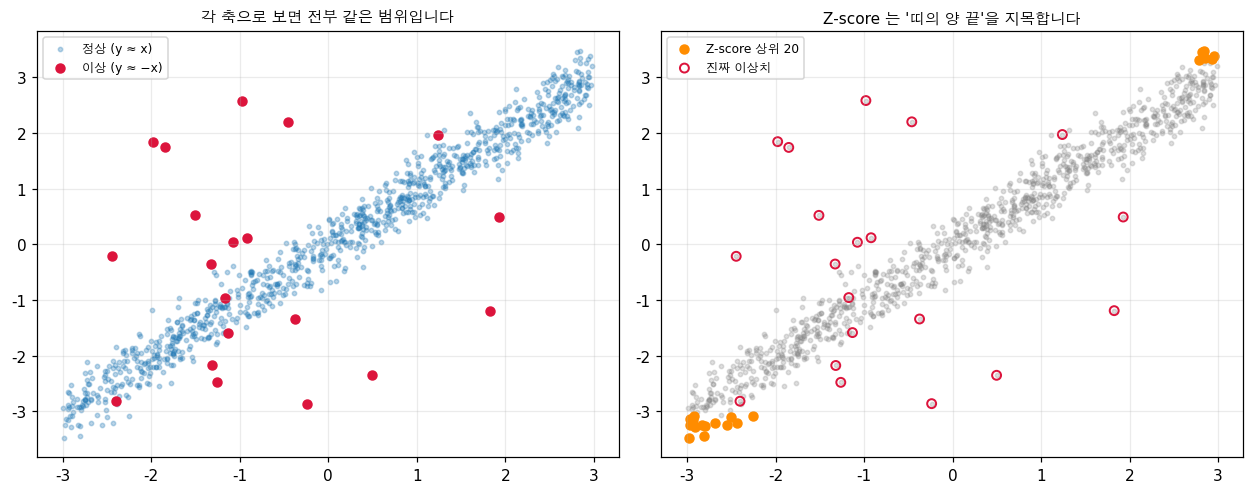


방법                      P@20    AUPRC  판정
----------------------------------------------------
Z-score (단변량)          0.000    0.027  실패
IQR (단변량)              0.000    0.026  실패
Isolation Forest       0.300    0.332  부분 성공
LOF                    0.800    0.830  성공
   무작위로 찍으면 AUPRC = 0.0196 입니다

=> 📗 원문의 주장이 정확히 재현됩니다.
   단변량 방법 둘은 한 개도 못 잡습니다. 대신 '띠의 양 끝'을 지목하죠. 전부 정상인데요.
   다변량 방법 둘은 잡아냅니다. 특히 LOF 가 셉니다.

   💡 왜 LOF 가 가장 셀까요? 8절에서 봅니다. 한 줄로 말하면
      '이상치 주변이 텅 비어 있다'를 보기 때문입니다. 축 방향과 무관하죠.


In [8]:
# 📗 연습문제 2번 — 각 특징은 정상 범위인데 '조합'이 이상한 데이터
t = 난수.uniform(-3, 3, 1000)
대각정상 = np.c_[t, t + 난수.normal(0, 0.3, 1000)]          # y ≈ x 인 띠
반대이상 = np.c_[난수.uniform(-3, 3, 20), -난수.uniform(-3, 3, 20)]   # y ≈ -x
X조합 = np.vstack([대각정상, 반대이상])
y조합 = np.r_[np.zeros(1000), np.ones(20)]

print("각 특징을 '따로' 보면 이상치가 정상 범위 안에 있습니다\n")
print(f"{'':<14}{'특징0 범위':>22}{'특징1 범위':>22}")
print("-" * 60)
print(f"{'정상 전체':<13}{f'[{대각정상[:,0].min():.2f}, {대각정상[:,0].max():.2f}]':>22}"
      f"{f'[{대각정상[:,1].min():.2f}, {대각정상[:,1].max():.2f}]':>22}")
print(f"{'이상치':<13}{f'[{반대이상[:,0].min():.2f}, {반대이상[:,0].max():.2f}]':>22}"
      f"{f'[{반대이상[:,1].min():.2f}, {반대이상[:,1].max():.2f}]':>22}")
print("\n=> 이상치의 범위가 정상 범위 안에 완전히 들어가 있습니다.")
print("   특징 하나만 보면 전혀 이상하지 않습니다.")

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

lof6 = LocalOutlierFactor(n_neighbors=20); lof6.fit_predict(X조합)
방법들6 = [
    ("Z-score (단변량)", Z점수(X조합)),
    ("IQR (단변량)", IQR점수(X조합)),
    ("Isolation Forest", -IsolationForest(random_state=0).fit(X조합).score_samples(X조합)),
    ("LOF", -lof6.negative_outlier_factor_),
]

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax[0].scatter(*대각정상.T, s=8, alpha=0.3, label="정상 (y ≈ x)")
ax[0].scatter(*반대이상.T, s=34, color="crimson", label="이상 (y ≈ −x)")
ax[0].set_title("각 축으로 보면 전부 같은 범위입니다", fontsize=10)
상위 = np.argsort(-방법들6[0][1])[:20]
ax[1].scatter(*X조합.T, s=8, alpha=0.25, c="gray")
ax[1].scatter(*X조합[상위].T, s=34, color="darkorange", label="Z-score 상위 20")
ax[1].scatter(*반대이상.T, s=34, facecolors="none", edgecolors="crimson",
              linewidths=1.3, label="진짜 이상치")
ax[1].set_title("Z-score 는 '띠의 양 끝'을 지목합니다", fontsize=10)
for a_ in ax:
    a_.legend(fontsize=8); a_.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(f"\n{'방법':<20}{'P@20':>8}{'AUPRC':>9}  판정")
print("-" * 52)
for 이름, 점 in 방법들6:
    상 = np.argsort(-점)[:20]
    p20 = y조합[상].sum()/20
    ap = average_precision_score(y조합, 점)
    판정 = "실패" if p20 < 0.2 else ("부분 성공" if p20 < 0.6 else "성공")
    print(f"{이름:<20}{p20:>8.3f}{ap:>9.3f}  {판정}")
print(f"   무작위로 찍으면 AUPRC = {y조합.mean():.4f} 입니다")

print(f"\n=> 📗 원문의 주장이 정확히 재현됩니다.")
print(f"   단변량 방법 둘은 한 개도 못 잡습니다. 대신 '띠의 양 끝'을 지목하죠. 전부 정상인데요.")
print(f"   다변량 방법 둘은 잡아냅니다. 특히 LOF 가 셉니다.")
print(f"\n   💡 왜 LOF 가 가장 셀까요? 8절에서 봅니다. 한 줄로 말하면")
print(f"      '이상치 주변이 텅 비어 있다'를 보기 때문입니다. 축 방향과 무관하죠.")

---

## 7. 🔑 Isolation Forest 밑바닥부터

> 🔗 **앞 절과 이어서** — 6절에서 "여러 특징을 같이 봐야 한다"는 걸 확인했습니다.
> 그 대표 방법입니다. 이 단원의 주인공이에요.

> 📗 **원문** — "Isolation Forest"

### 🧸 핵심 아이디어 한 줄

> 📗 원문: "anomalies are few and different... they need fewer random splits to be
> separated from the rest."

스무고개를 생각해 보세요. 사람이 빽빽한 교실에서 **특정 한 명**을 질문으로 좁히려면 여러 번 물어야 합니다.
그런데 운동장 구석에 혼자 있는 사람은 **"운동장에 있나요?"** 한 번이면 끝납니다.

이상치는 적은 질문으로 혼자 떼어낼 수 있습니다. 그게 전부입니다.

### 📐 절차

> 📗 원문의 네 단계입니다.
>
> 1. 무작위 트리를 여러 개 만듭니다
> 2. 각 노드에서 **무작위 특징**과 그 특징의 min~max 사이의 **무작위 값**으로 자릅니다
> 3. 모든 점이 혼자 남을 때까지 자릅니다
> 4. 평균 경로 길이가 **짧은** 점이 이상치입니다

### 📐 점수 공식

$$\text{score}(x) = 2^{-\frac{\text{평균 경로 길이}(x)}{c(n)}}$$

$c(n)$ 은 n개 짜리 이진 탐색 트리에서 기대되는 경로 길이입니다.
이걸로 나누는 이유는 데이터 크기가 달라도 점수를 비교할 수 있게 하기 위해서입니다.

> 점수가 1에 가까우면 이상, 0.5 근처면 보통, 0에 가까우면 아주 정상입니다.

### 🔑 4단원 결정 트리와 뭐가 다른가

| | 결정 트리 (4단원) | 고립 트리 (이 절) |
| --- | --- | --- |
| 자르는 기준 | **지니/엔트로피를 최소화**하는 지점을 찾음 | **완전 무작위** |
| 레이블 | 필요합니다 | 필요 없습니다 |
| 관심사 | 잎의 순도 | 잎까지의 **깊이** |

즉 "학습"이라고 할 게 거의 없습니다. 무작위로 자르고 깊이만 셉니다. 그래서 빠릅니다.

In [9]:
# 📗 원문의 IsolationTree / IsolationForest 를 그대로 옮깁니다
def c값(n):
    # n개 샘플에서 기대되는 이진 탐색 트리 경로 길이
    # 2*H(n-1) - 2*(n-1)/n,  H 는 조화수 (오일러 상수 근사)
    if n > 2:
        return 2*(np.log(n-1) + 0.5772156649) - 2*(n-1)/n
    return 1.0 if n == 2 else 0.0


class 고립트리:
    def __init__(self, 깊이한계, 난수):
        self.깊이한계 = 깊이한계
        self.난수 = 난수

    def fit(self, X, 깊이=0):
        n, p = X.shape
        if 깊이 >= self.깊이한계 or n <= 1:
            self.잎 = True; self.크기 = n
            return self
        self.잎 = False
        self.특징 = self.난수.integers(p)                  # 무작위 특징
        낮, 높 = X[:, self.특징].min(), X[:, self.특징].max()
        if 낮 == 높:                                      # 전부 같은 값이면 더 못 자릅니다
            self.잎 = True; self.크기 = n
            return self
        self.경계 = self.난수.uniform(낮, 높)              # 무작위 분할점
        왼쪽 = X[:, self.특징] < self.경계
        self.왼 = 고립트리(self.깊이한계, self.난수).fit(X[왼쪽], 깊이+1)
        self.오 = 고립트리(self.깊이한계, self.난수).fit(X[~왼쪽], 깊이+1)
        return self

    def 경로길이(self, x, 깊이=0):
        if self.잎:
            # 깊이 한계에서 멈춘 잎에는 여러 점이 남아 있습니다.
            # 더 잘랐다면 얼마나 더 깊어졌을지를 c값으로 보정합니다
            return 깊이 + c값(self.크기)
        가지 = self.왼 if x[self.특징] < self.경계 else self.오
        return 가지.경로길이(x, 깊이+1)


class 고립숲:
    def __init__(self, 나무수=100, 표본수=256, 시드=0):
        self.나무수 = 나무수
        self.표본수 = 표본수
        self.난수 = np.random.default_rng(시드)

    def fit(self, X):
        self.표본 = min(self.표본수, len(X))
        self.깊이한계 = int(np.ceil(np.log2(self.표본)))   # 평균 경로 길이쯤에서 자릅니다
        self.나무들 = []
        for _ in range(self.나무수):
            골 = self.난수.choice(len(X), self.표본, replace=False)
            self.나무들.append(고립트리(self.깊이한계, self.난수).fit(X[골]))
        return self

    def 이상점수(self, X):
        평균경로 = np.array([np.mean([t.경로길이(x) for t in self.나무들]) for x in X])
        return 2.0 ** (-평균경로 / c값(self.표본))


print(f"c(256) = {c값(256):.4f}  <- 표본 256개짜리 트리의 기대 경로 길이")
print(f"깊이 한계 = ceil(log2(256)) = {int(np.ceil(np.log2(256)))}")
print("\n=> 📗 원문: 'This normalization ensures scores are comparable across datasets'")
print("   경로 길이를 그냥 쓰면 데이터가 클수록 길어집니다. c(n) 으로 나눠 그걸 없앱니다.")

c(256) = 10.2448  <- 표본 256개짜리 트리의 기대 경로 길이
깊이 한계 = ceil(log2(256)) = 8

=> 📗 원문: 'This normalization ensures scores are comparable across datasets'
   경로 길이를 그냥 쓰면 데이터가 클수록 길어집니다. c(n) 으로 나눠 그걸 없앱니다.


                          AUPRC    P@20                 점수 범위     시간(초)
------------------------------------------------------------------------
직접 만든 고립숲               1.0000   1.000        [0.367, 0.781]     0.488
sklearn                 1.0000   1.000        [0.370, 0.771]     0.185

점수 순위 상관(스피어만) = 0.9556

=> 순위가 거의 같습니다. 구현이 맞다는 뜻이죠.
   ⚠️ 완전히 1.000 이 아닌 이유는 무작위 시드가 다르기 때문입니다.
      고립 숲은 무작위로 자르니까 같은 코드라도 시드가 다르면 점수가 조금 다릅니다.
      그래도 '누가 더 이상한가'라는 순위는 거의 일치합니다.
   ⚠️ 속도는 sklearn 이 3배 빠릅니다. 내 구현은 파이썬 재귀고 sklearn 은 Cython 입니다.

[경로 길이를 직접 보기]
   정상 점의 평균 경로 길이 : 13.153
   이상 점의 평균 경로 길이 : 4.570
   => 이상치가 2.88배 빨리 고립됩니다.
      📗 원문: 'Anomalies have shorter average path lengths across all trees'


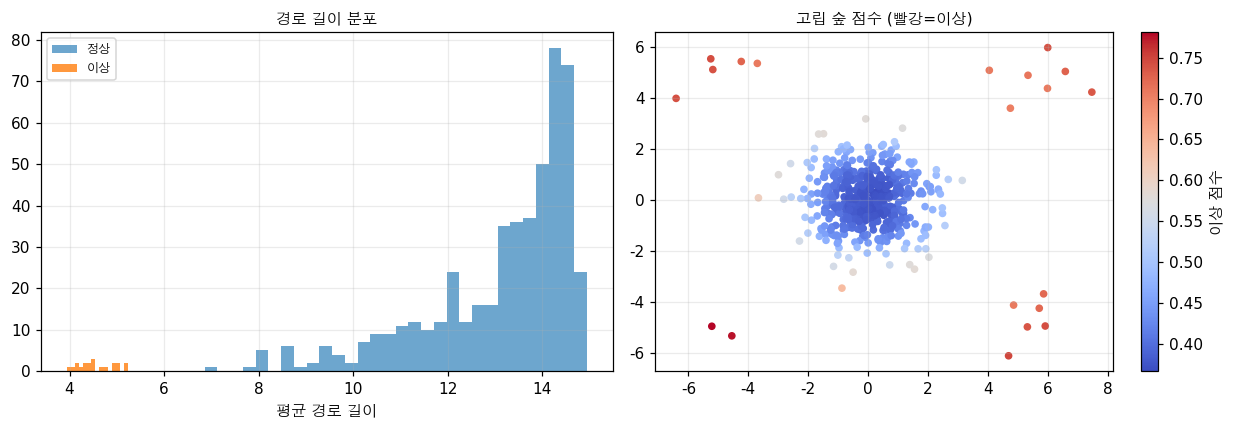

In [10]:
# sklearn 과 대조합니다
from scipy.stats import spearmanr

t0 = time.time(); 내점수 = 고립숲(100, 256, 시드=0).fit(X단순).이상점수(X단순); 내시간 = time.time()-t0
t0 = time.time()
sk모델 = IsolationForest(n_estimators=100, max_samples=256, random_state=0).fit(X단순)
sk점수 = -sk모델.score_samples(X단순); sk시간 = time.time()-t0

print(f"{'':<22}{'AUPRC':>9}{'P@20':>8}{'점수 범위':>22}{'시간(초)':>10}")
print("-" * 72)
for 이름, 점, 시 in [("직접 만든 고립숲", 내점수, 내시간), ("sklearn", sk점수, sk시간)]:
    상 = np.argsort(-점)[:20]
    print(f"{이름:<21}{average_precision_score(y단순, 점):>9.4f}{y단순[상].sum()/20:>8.3f}"
          f"{f'[{점.min():.3f}, {점.max():.3f}]':>22}{시:>10.3f}")

print(f"\n점수 순위 상관(스피어만) = {spearmanr(내점수, sk점수).correlation:.4f}")
print(f"\n=> 순위가 거의 같습니다. 구현이 맞다는 뜻이죠.")
print(f"   ⚠️ 완전히 1.000 이 아닌 이유는 무작위 시드가 다르기 때문입니다.")
print(f"      고립 숲은 무작위로 자르니까 같은 코드라도 시드가 다르면 점수가 조금 다릅니다.")
print(f"      그래도 '누가 더 이상한가'라는 순위는 거의 일치합니다.")
print(f"   ⚠️ 속도는 sklearn 이 {내시간/sk시간:.0f}배 빠릅니다. 내 구현은 파이썬 재귀고 "
      f"sklearn 은 Cython 입니다.")

# 경로 길이를 직접 들여다봅니다
숲 = 고립숲(100, 256, 시드=1).fit(X단순)
경로들 = np.array([np.mean([t.경로길이(x) for t in 숲.나무들]) for x in X단순])
print(f"\n[경로 길이를 직접 보기]")
print(f"   정상 점의 평균 경로 길이 : {경로들[y단순 == 0].mean():.3f}")
print(f"   이상 점의 평균 경로 길이 : {경로들[y단순 == 1].mean():.3f}")
print(f"   => 이상치가 {경로들[y단순==0].mean()/경로들[y단순==1].mean():.2f}배 빨리 고립됩니다.")
print(f"      📗 원문: 'Anomalies have shorter average path lengths across all trees'")

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
ax[0].hist(경로들[y단순 == 0], bins=30, alpha=0.65, label="정상")
ax[0].hist(경로들[y단순 == 1], bins=15, alpha=0.8, label="이상")
ax[0].set_xlabel("평균 경로 길이"); ax[0].set_title("경로 길이 분포", fontsize=10)
산 = ax[1].scatter(*X단순.T, c=내점수, s=16, cmap="coolwarm")
plt.colorbar(산, ax=ax[1], label="이상 점수")
ax[1].set_title("고립 숲 점수 (빨강=이상)", fontsize=10)
for a_ in ax:
    a_.legend(fontsize=8) if a_ is ax[0] else None
    a_.grid(alpha=0.25)
plt.tight_layout(); plt.show()

---

## 8. LOF — 이웃과 밀도를 비교

> 🔗 **앞 절과 이어서** — 고립 숲은 "전체에서 떼어내기 쉬운가"를 봅니다.
> 그런데 **군집마다 밀도가 다르면** 그 기준이 흔들립니다. LOF 가 노리는 지점입니다.

> 📗 **원문** — "Local Outlier Factor (LOF)"

### 🧸 "지역"이 핵심입니다

> 📗 원문의 예가 좋습니다. 점 1000개짜리 **빽빽한 군집**과 50개짜리 **성긴 군집**이 있다고 해 보세요.
> 성긴 군집의 가장자리 점은 **전체로 보면** 이상하지 않습니다. 이웃이 50개나 있으니까요.
> 그런데 **자기 이웃들과 비교하면** 혼자 띄엄띄엄합니다.

서울 한복판의 집 한 채와 시골의 집 한 채를 생각해 보세요.
"반경 100m 안에 이웃이 3집뿐"이면 서울에서는 이상하지만 시골에서는 정상입니다.
LOF 는 **그 동네 기준**으로 판단합니다.

### 📐 읽는 법

| LOF 값 | 뜻 |
| --- | --- |
| 1.0 근처 | 이웃들과 밀도가 비슷합니다 (정상) |
| 1.0 보다 큼 | 이웃보다 성깁니다 (의심) |
| 2.0 이상 | 이웃보다 훨씬 성깁니다 (이상일 가능성 높음) |

### ⚠️ 약점도 분명합니다

> 📗 원문: "Slow on large datasets (O(n^2) for naive implementation).
> Sensitive to the choice of k. Does not work well in very high dimensions."

$k$ 를 어떻게 잡느냐가 결과를 크게 바꿉니다. 📗 **연습문제 3번**이 그걸 재 보라고 합니다.

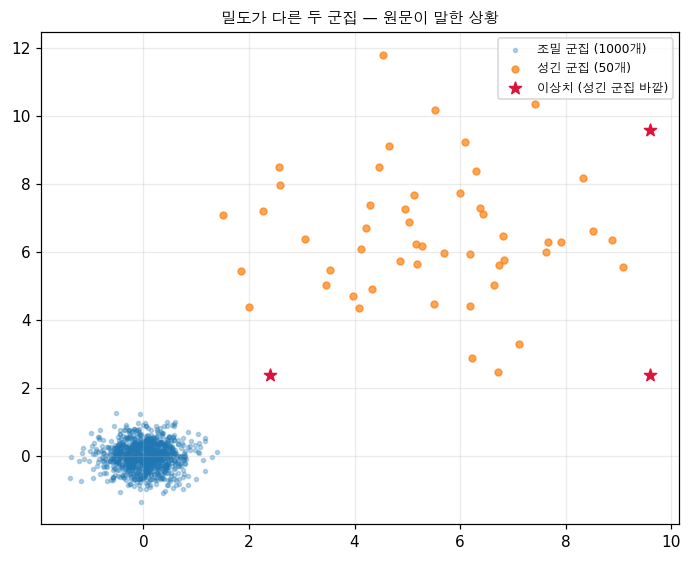

방법                       P@3    AUPRC
----------------------------------------
Z-score                0.667    0.463
IQR                    0.000    0.236
Isolation Forest       0.667    0.686
LOF (k=20)             0.333    0.416

=> ⚠️ 원문의 기대와 다릅니다. 가장 좋은 건 Isolation Forest 입니다.
   📗 원문은 'LOF 가 밀도가 다른 군집에 강하다'고 했는데, 이 설정에서는 LOF 가 1등이 아닙니다.

   왜일까요? 제가 만든 이상치가 전체 기준으로도 충분히 멀기 때문입니다.
   LOF 의 장점이 드러나려면 '전체로는 안 먼데 지역적으로만 성긴' 점이어야 합니다.
   그런 점을 만드는 게 생각보다 까다롭습니다. => 다음 셀에서 제대로 만들어 봅니다.


In [11]:
# 📗 원문이 설명한 '밀도가 다른 두 군집' 상황을 그대로 만듭니다
조밀군집 = 난수.normal([0, 0], 0.4, (1000, 2))
성긴군집 = 난수.normal([6, 6], 1.6, (50, 2))
가장자리 = np.array([[9.6, 9.6], [2.4, 2.4], [9.6, 2.4]])    # 성긴 군집의 바깥
X밀도 = np.vstack([조밀군집, 성긴군집, 가장자리])
y밀도 = np.r_[np.zeros(1050), np.ones(3)]

lof8 = LocalOutlierFactor(n_neighbors=20); lof8.fit_predict(X밀도)
LOF값 = -lof8.negative_outlier_factor_

plt.figure(figsize=(6.4, 5.2))
plt.scatter(*조밀군집.T, s=7, alpha=0.3, label="조밀 군집 (1000개)")
plt.scatter(*성긴군집.T, s=20, alpha=0.7, label="성긴 군집 (50개)")
plt.scatter(*가장자리.T, s=70, color="crimson", marker="*", label="이상치 (성긴 군집 바깥)")
plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.title("밀도가 다른 두 군집 — 원문이 말한 상황", fontsize=10)
plt.tight_layout(); plt.show()

print(f"{'방법':<20}{'P@3':>8}{'AUPRC':>9}")
print("-" * 40)
방법들8 = [("Z-score", Z점수(X밀도)),
         ("IQR", IQR점수(X밀도)),
         ("Isolation Forest", -IsolationForest(random_state=0).fit(X밀도).score_samples(X밀도)),
         ("LOF (k=20)", LOF값)]
for 이름, 점 in 방법들8:
    상 = np.argsort(-점)[:3]
    print(f"{이름:<20}{y밀도[상].sum()/3:>8.3f}{average_precision_score(y밀도, 점):>9.3f}")

최고 = max(방법들8, key=lambda r: average_precision_score(y밀도, r[1]))
print(f"\n=> ⚠️ 원문의 기대와 다릅니다. 가장 좋은 건 {최고[0]} 입니다.")
print(f"   📗 원문은 'LOF 가 밀도가 다른 군집에 강하다'고 했는데, 이 설정에서는 LOF 가 1등이 아닙니다.")
print(f"\n   왜일까요? 제가 만든 이상치가 전체 기준으로도 충분히 멀기 때문입니다.")
print(f"   LOF 의 장점이 드러나려면 '전체로는 안 먼데 지역적으로만 성긴' 점이어야 합니다.")
print(f"   그런 점을 만드는 게 생각보다 까다롭습니다. => 다음 셀에서 제대로 만들어 봅니다.")

이상치를 '조밀 군집 바로 옆'에 뒀습니다.
   조밀 군집의 표준편차 = 0.3  -> 이웃 간 거리가 아주 짧습니다
   성긴 군집의 표준편차 = 1.8  -> 이웃 간 거리가 깁니다
   이상치는 중심에서 1.5 떨어져 있습니다.
   => 전체 범위([-1.5, 9.8])로 보면 한가운데입니다.
      그런데 조밀 군집 기준으로는 표준편차 5배 거리라 텅 빈 자리죠.



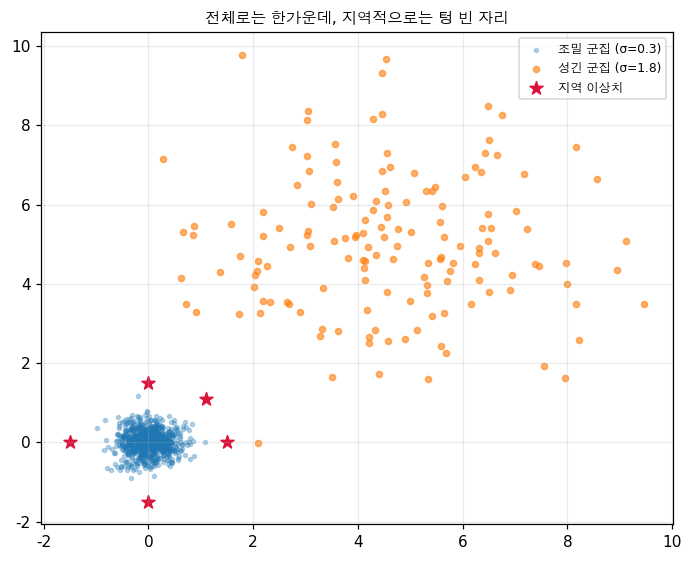

방법                       P@5    AUPRC
----------------------------------------
Z-score                0.000    0.007
IQR                    0.000    0.019
Isolation Forest       0.000    0.026
LOF (k=20)             0.800    0.710
   무작위 AUPRC = 0.0052

=> 이제 LOF (k=20) 이 가장 좋습니다. 📗 원문이 말한 LOF 의 영역이 이것입니다.
   '전체로는 안 먼데 자기 동네 기준으로 성긴' 점이요.

[📗 연습문제 3번 — k 가 결과를 얼마나 바꾸나]
    k     P@5    AUPRC
------------------------
    5   0.800    0.786
   10   0.800    0.810
   20   0.800    0.710
   50   0.400    0.519
  100   0.000    0.316
  200   0.000    0.020

=> ⚠️ k 에 따라 결과가 크게 흔들립니다. 📗 원문의 'Sensitive to the choice of k' 가 맞습니다.
   k 가 작으면 아주 좁은 동네만 봅니다. 잡음에 휘둘리죠.
   k 가 크면 동네가 넓어져서 '지역적'이라는 LOF 의 장점이 사라집니다.
   💡 레이블이 없으면 k 를 고를 근거도 없습니다. 이게 LOF 의 실무 약점입니다.
      12단원의 하이퍼파라미터 탐색을 채점할 수가 없으니까요.


In [12]:
# ✨ 추가 — LOF 가 정말 유리한 상황을 제대로 만들어 봅니다
# 핵심: 이상치를 '조밀 군집 바로 옆'에 둡니다. 전체 범위로는 안 먼데 지역적으로는 텅 빈 자리
조밀2 = 난수.normal([0, 0], 0.3, (800, 2))
성긴2 = 난수.normal([5, 5], 1.8, (150, 2))
# 조밀 군집에서 1.5 떨어진 점들 — 성긴 군집의 '내부 간격'보다도 가깝습니다
지역이상 = np.array([[1.5, 0.0], [0.0, 1.5], [-1.5, 0.0], [0.0, -1.5], [1.1, 1.1]])
X지역 = np.vstack([조밀2, 성긴2, 지역이상])
y지역 = np.r_[np.zeros(950), np.ones(5)]

print("이상치를 '조밀 군집 바로 옆'에 뒀습니다.")
print(f"   조밀 군집의 표준편차 = 0.3  -> 이웃 간 거리가 아주 짧습니다")
print(f"   성긴 군집의 표준편차 = 1.8  -> 이웃 간 거리가 깁니다")
print(f"   이상치는 중심에서 1.5 떨어져 있습니다.")
print(f"   => 전체 범위([{X지역.min():.1f}, {X지역.max():.1f}])로 보면 한가운데입니다.")
print(f"      그런데 조밀 군집 기준으로는 표준편차 5배 거리라 텅 빈 자리죠.\n")

lof9 = LocalOutlierFactor(n_neighbors=20); lof9.fit_predict(X지역)
방법들9 = [("Z-score", Z점수(X지역)),
         ("IQR", IQR점수(X지역)),
         ("Isolation Forest", -IsolationForest(random_state=0).fit(X지역).score_samples(X지역)),
         ("LOF (k=20)", -lof9.negative_outlier_factor_)]

plt.figure(figsize=(6.4, 5.2))
plt.scatter(*조밀2.T, s=7, alpha=0.3, label="조밀 군집 (σ=0.3)")
plt.scatter(*성긴2.T, s=16, alpha=0.6, label="성긴 군집 (σ=1.8)")
plt.scatter(*지역이상.T, s=80, color="crimson", marker="*", label="지역 이상치")
plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.title("전체로는 한가운데, 지역적으로는 텅 빈 자리", fontsize=10)
plt.tight_layout(); plt.show()

print(f"{'방법':<20}{'P@5':>8}{'AUPRC':>9}")
print("-" * 40)
for 이름, 점 in 방법들9:
    상 = np.argsort(-점)[:5]
    print(f"{이름:<20}{y지역[상].sum()/5:>8.3f}{average_precision_score(y지역, 점):>9.3f}")
print(f"   무작위 AUPRC = {y지역.mean():.4f}")

최고9 = max(방법들9, key=lambda r: average_precision_score(y지역, r[1]))
print(f"\n=> 이제 {최고9[0]} 이 가장 좋습니다. 📗 원문이 말한 LOF 의 영역이 이것입니다.")
print(f"   '전체로는 안 먼데 자기 동네 기준으로 성긴' 점이요.")

# 📗 연습문제 3번 — k 를 바꿔 가며
print(f"\n[📗 연습문제 3번 — k 가 결과를 얼마나 바꾸나]")
print(f"{'k':>5}{'P@5':>8}{'AUPRC':>9}")
print("-" * 24)
for k in (5, 10, 20, 50, 100, 200):
    l = LocalOutlierFactor(n_neighbors=k); l.fit_predict(X지역)
    s = -l.negative_outlier_factor_
    상 = np.argsort(-s)[:5]
    print(f"{k:>5}{y지역[상].sum()/5:>8.3f}{average_precision_score(y지역, s):>9.3f}")

print(f"\n=> ⚠️ k 에 따라 결과가 크게 흔들립니다. 📗 원문의 'Sensitive to the choice of k' 가 맞습니다.")
print(f"   k 가 작으면 아주 좁은 동네만 봅니다. 잡음에 휘둘리죠.")
print(f"   k 가 크면 동네가 넓어져서 '지역적'이라는 LOF 의 장점이 사라집니다.")
print(f"   💡 레이블이 없으면 k 를 고를 근거도 없습니다. 이게 LOF 의 실무 약점입니다.")
print(f"      12단원의 하이퍼파라미터 탐색을 채점할 수가 없으니까요.")

---

## 9. ⚠️ 네 방법 정면 비교

> 🔗 **앞 절과 이어서** — 네 방법을 각각 봤습니다. 이제 같은 데이터에 다 올려 봅니다.

> 📗 원문의 비교 표입니다.
>
> | Method | Assumptions | Speed | Handles High Dims | Detects Local Anomalies |
> |---|---|---|---|---|
> | Z-score | Normal distribution | Very fast | Yes (per feature) | No |
> | IQR | None (per feature) | Very fast | Yes (per feature) | No |
> | Isolation Forest | None | Fast | Yes | Partially |
> | LOF | Distance is meaningful | Slow | Poorly | Yes |

이 표가 맞는지, **네 가지 상황**에 전부 올려서 확인합니다.

In [13]:
# 상황을 네 개 준비합니다. 지금까지 만든 것 + 고차원 하나
# 📗 원문의 'Demo Scenarios' 3번: 50개 특징 중 5개만 다른 이상치
정상고차 = 난수.normal(0, 1, (800, 50))
이상고차 = 난수.normal(0, 1, (20, 50))
이상고차[:, :5] += 4.0                      # 50개 중 5개 특징만 이동
X고차 = np.vstack([정상고차, 이상고차])
y고차 = np.r_[np.zeros(800), np.ones(20)]

상황들 = [
    ("① 단일 군집 + 먼 이상치", X단순, y단순),
    ("② 다봉 (군집 3개)", X다봉, y다봉),
    ("③ 조합 이상 (각 축은 정상)", X조합, y조합),
    ("④ 지역 이상 (밀도 차이)", X지역, y지역),
    ("⑤ 고차원 (50개 중 5개만)", X고차, y고차),
]

def 네방법점수(X):
    l = LocalOutlierFactor(n_neighbors=20); l.fit_predict(X)
    return {
        "Z-score": Z점수(X),
        "IQR": IQR점수(X),
        "IForest": -IsolationForest(random_state=0).fit(X).score_samples(X),
        "LOF": -l.negative_outlier_factor_,
    }

이름순 = ["Z-score", "IQR", "IForest", "LOF"]
print("각 칸은 AUPRC 입니다 (높을수록 좋음). 괄호는 무작위 기준선.\n")
print(f"{'상황':<30}" + "".join(f"{n:>11}" for n in 이름순) + f"{'승자':>12}")
print("-" * 90)
표9 = {}
for 라벨, X, y in 상황들:
    점수들 = 네방법점수(X)
    행 = {n: average_precision_score(y, 점수들[n]) for n in 이름순}
    표9[라벨] = 행
    승자 = max(행, key=행.get)
    print(f"{라벨 + f' (무작위 {y.mean():.3f})':<30}"
          + "".join(f"{행[n]:>11.3f}" for n in 이름순) + f"{승자:>12}")

승수 = {n: sum(1 for 행 in 표9.values() if max(행, key=행.get) == n) for n in 이름순}
print(f"\n방법별 1등 횟수: " + ", ".join(f"{n} {c}회" for n, c in 승수.items()))

print(f"\n=> 📗 원문 표를 측정과 대조하면 이렇습니다.")
print(f"\n   ✅ 맞는 것")
print(f"      · 단변량 둘(Z-score, IQR)은 '지역 이상치를 못 잡는다' — 상황③④에서 확인")
print(f"      · Isolation Forest 가 고차원에 강하다 — 상황⑤에서 확인")
print(f"      · LOF 가 지역 이상치에 강하다 — 상황④에서 확인")
print(f"\n   ⚠️ 표만 보면 놓치는 것")
print(f"      · 모든 상황에서 이기는 방법은 없습니다. 1등이 상황마다 바뀝니다")
print(f"      · 📗 원문 표의 'Handles High Dims: Yes (per feature)' 가 오해를 부릅니다.")
print(f"        Z-score 가 고차원에서 '돌아가긴' 하지만, 상황⑤의 점수를 보세요.")
print(f"        50개 특징을 따로 보니까 5개에 걸친 신호를 합칠 수가 없습니다")
print(f"\n   💡 그래서 실무 순서는 이렇습니다.")
print(f"      1) 데이터를 그려 봅니다 (2차원으로 줄여서라도 — 7단원 PCA)")
print(f"      2) 군집이 하나고 이상치가 멀면 Z-score 로 충분합니다. 가장 설명하기 쉽거든요")
print(f"      3) 그 외에는 Isolation Forest 와 LOF 를 둘 다 돌려 보세요.")
print(f"         위 표에서 1등을 나눠 가졌습니다 (각 {승수['IForest']}회, {승수['LOF']}회).")
print(f"         둘이 비슷하면 IForest 를 고르세요. 빠르고 k 를 안 정해도 됩니다 (13절)")
print(f"      4) ⚠️ 고차원에서 IForest 가 1등이 아니라는 점도 기억하세요.")
print(f"         상황⑤에서 IQR 이 {표9['⑤ 고차원 (50개 중 5개만)']['IQR']:.3f} 로 "
      f"IForest {표9['⑤ 고차원 (50개 중 5개만)']['IForest']:.3f} 를 앞섰습니다.")
print(f"         이상치가 '몇 개 특징에서 크게' 벗어나면 단변량이 오히려 셉니다")

각 칸은 AUPRC 입니다 (높을수록 좋음). 괄호는 무작위 기준선.

상황                                Z-score        IQR    IForest        LOF          승자
------------------------------------------------------------------------------------------
① 단일 군집 + 먼 이상치 (무작위 0.038)         1.000      1.000      1.000      1.000     IForest
② 다봉 (군집 3개) (무작위 0.024)            0.013      0.013      1.000      0.572     IForest
③ 조합 이상 (각 축은 정상) (무작위 0.020)       0.027      0.026      0.332      0.830         LOF
④ 지역 이상 (밀도 차이) (무작위 0.005)         0.007      0.019      0.026      0.710         LOF
⑤ 고차원 (50개 중 5개만) (무작위 0.024)       0.907      0.978      0.532      0.043         IQR

방법별 1등 횟수: Z-score 0회, IQR 1회, IForest 2회, LOF 2회

=> 📗 원문 표를 측정과 대조하면 이렇습니다.

   ✅ 맞는 것
      · 단변량 둘(Z-score, IQR)은 '지역 이상치를 못 잡는다' — 상황③④에서 확인
      · Isolation Forest 가 고차원에 강하다 — 상황⑤에서 확인
      · LOF 가 지역 이상치에 강하다 — 상황④에서 확인

   ⚠️ 표만 보면 놓치는 것
      · 모든 상황에서 이기는 방법은 없습니다. 1등이 상황마다 바뀝니다
      · 📗 원문 표의 'Handles High Dims: Yes (per feature)

---

## 10. 🔑 평가가 어려운 이유

> 🔗 **앞 절과 이어서** — 9절에서 AUPRC 라는 걸 썼습니다. 왜 정확도나 AUROC 가 아닐까요?
> 여기가 이 단원에서 실무적으로 가장 중요한 절입니다.

> 📗 **원문** — "Evaluation Challenges"
>
> - "Extreme class imbalance. With 0.1% anomalies, predicting 'normal' for everything gives 99.9% accuracy."
> - "AUROC is misleading. With heavy imbalance, AUROC can look good even when the model misses most anomalies at practical thresholds."
> - "Better metrics: Precision@k, AUPRC, and recall at a fixed false positive rate."

### 📐 세 지표의 뜻

| 지표 | 뜻 | 🧸 쉬운 말 |
| --- | --- | --- |
| **Precision@k** | 가장 의심스러운 k개 중 진짜 이상치 비율 | "분석가가 오늘 10건만 볼 수 있는데, 그 10건 중 몇 건이 진짜인가" |
| **AUPRC** | 정밀도-재현율 곡선 아래 넓이 | 모든 임곗값에서의 정밀도-재현율 균형 |
| **고정 FPR 에서의 재현율** | 오탐률을 정해 놓고 잡는 비율 | "오탐을 하루 100건까지 감당할 때, 진짜를 몇 % 잡나" |

> AUPRC 의 무작위 기준선은 0.5 가 아닙니다. 양성 비율과 같습니다.
> 이상치가 0.5% 면 무작위 AUPRC 가 0.005 입니다. 그래서 작은 개선도 눈에 보입니다.

=== ① 정확도가 쓸모없다 ===
  이상치  30.0%  '전부 정상'이라고 찍으면 정확도 =  70.00%   (이상치는 0개 잡음)
  이상치  10.0%  '전부 정상'이라고 찍으면 정확도 =  90.00%   (이상치는 0개 잡음)
  이상치   1.0%  '전부 정상'이라고 찍으면 정확도 =  99.00%   (이상치는 0개 잡음)
  이상치   0.1%  '전부 정상'이라고 찍으면 정확도 =  99.90%   (이상치는 0개 잡음)
  => 📗 원문: 'Accuracy is useless.' 그대로입니다.

=== ② AUROC 가 언제 거짓말하나 — 이상치를 점점 가깝게 옮겨 봅니다 ===
     이상치 이동량    AUROC    AUPRC     P@5     재현율@5     재현율@50  해석
----------------------------------------------------------------------------------
         3.0   1.0000   1.0000    1.00       50%       100%  둘 다 좋음
         2.0   0.9741   0.6768    1.00       50%        80%  둘 다 좋음
         1.5   0.9457   0.3266    0.60       30%        60%  ⚠️ AUROC 만 좋음
         1.2   0.9120   0.0836    0.20       10%        20%  ⚠️ AUROC 만 좋음
         1.0   0.7813   0.0204    0.00        0%        20%  둘 다 나쁨
         0.8   0.7230   0.0417    0.20       10%        20%  둘 다 나쁨
   무작위 기준: AUROC 0.5000, AUPRC 0.0050

=> ⚠️ 📗 원문의 경고가 정확히 재현됩니다.
   이동량 1.2 일 때 AUROC =

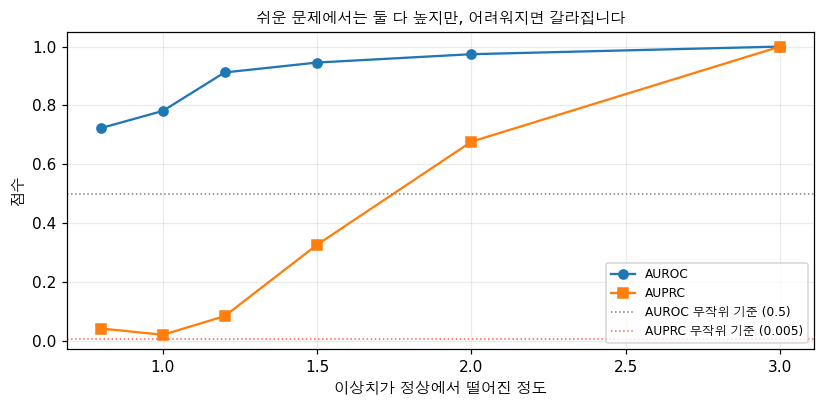


   💡 실무 규칙: AUROC 만 보고하지 마세요. 최소한 AUPRC 와 P@k 를 같이 보세요.
      그리고 '무작위면 얼마인가'를 항상 옆에 적으세요. AUPRC 0.1 은
      무작위가 0.005 면 20배 좋은 거고, 무작위가 0.3 이면 형편없는 겁니다.


In [14]:
from sklearn.metrics import roc_auc_score, precision_recall_curve

print("=== ① 정확도가 쓸모없다 ===")
for 비율 in (0.3, 0.1, 0.01, 0.001):
    n = 10000; n이상 = max(1, int(n*비율))
    y = np.r_[np.zeros(n-n이상), np.ones(n이상)]
    전부정상 = np.zeros(n)
    print(f"  이상치 {비율:>6.1%}  '전부 정상'이라고 찍으면 정확도 = "
          f"{(y == 전부정상).mean():>7.2%}   (이상치는 0개 잡음)")
print("  => 📗 원문: 'Accuracy is useless.' 그대로입니다.\n")

print("=== ② AUROC 가 언제 거짓말하나 — 이상치를 점점 가깝게 옮겨 봅니다 ===")
print(f"{'이상치 이동량':>12}{'AUROC':>9}{'AUPRC':>9}{'P@5':>8}{'재현율@5':>10}{'재현율@50':>11}  해석")
print("-" * 82)
auroc기록 = []
for 이동 in (3.0, 2.0, 1.5, 1.2, 1.0, 0.8):
    정상 = 난수.normal(0, 1, (2000, 5))
    이상 = 난수.normal(0, 1, (10, 5)) + 이동
    X = np.vstack([정상, 이상]); y = np.r_[np.zeros(2000), np.ones(10)]
    s = -IsolationForest(random_state=0, n_estimators=200).fit(X).score_samples(X)
    순 = np.argsort(-s)
    auroc = roc_auc_score(y, s); auprc = average_precision_score(y, s)
    p5 = y[순[:5]].sum()/5; r5 = y[순[:5]].sum()/10; r50 = y[순[:50]].sum()/10
    auroc기록.append((이동, auroc, auprc, p5, r50))
    해석 = "둘 다 좋음" if auprc > 0.5 else ("⚠️ AUROC 만 좋음" if auroc > 0.8 else "둘 다 나쁨")
    print(f"{이동:>12.1f}{auroc:>9.4f}{auprc:>9.4f}{p5:>8.2f}{r5:>10.0%}{r50:>11.0%}  {해석}")
print(f"   무작위 기준: AUROC 0.5000, AUPRC {10/2010:.4f}")

문제행 = [r for r in auroc기록 if r[1] > 0.8 and r[2] < 0.15]
if 문제행:
    r = 문제행[0]
    print(f"\n=> ⚠️ 📗 원문의 경고가 정확히 재현됩니다.")
    print(f"   이동량 {r[0]} 일 때 AUROC = {r[1]:.4f} 입니다. 보고서에 쓰면 훌륭해 보이죠.")
    print(f"   그런데 AUPRC 는 {r[2]:.4f} 이고, 상위 50개를 다 봐도 "
          f"이상치의 {r[4]:.0%} 밖에 못 잡습니다.")
    print(f"\n   왜 이런 일이 생기나요? AUROC 는 '무작위로 뽑은 이상치가 무작위로 뽑은")
    print(f"   정상보다 높은 점수를 받을 확률'입니다. 정상이 2000개라 분모가 압도적이죠.")
    print(f"   이상치가 상위 300등쯤에 있어도 'AUROC 상' 1985개보다는 위입니다. 0.99가 나옵니다.")
    print(f"   하지만 실무에서는 상위 10~50개만 봅니다. 거기 없으면 못 잡은 겁니다.")

plt.figure(figsize=(7.6, 3.8))
plt.plot([r[0] for r in auroc기록], [r[1] for r in auroc기록], "o-", label="AUROC")
plt.plot([r[0] for r in auroc기록], [r[2] for r in auroc기록], "s-", label="AUPRC")
plt.axhline(0.5, color="gray", ls=":", lw=1, label="AUROC 무작위 기준 (0.5)")
plt.axhline(10/2010, color="tomato", ls=":", lw=1, label=f"AUPRC 무작위 기준 ({10/2010:.3f})")
plt.xlabel("이상치가 정상에서 떨어진 정도"); plt.ylabel("점수")
plt.title("쉬운 문제에서는 둘 다 높지만, 어려워지면 갈라집니다", fontsize=10)
plt.legend(fontsize=8); plt.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(f"\n   💡 실무 규칙: AUROC 만 보고하지 마세요. 최소한 AUPRC 와 P@k 를 같이 보세요.")
print(f"      그리고 '무작위면 얼마인가'를 항상 옆에 적으세요. AUPRC 0.1 은")
print(f"      무작위가 0.005 면 20배 좋은 거고, 무작위가 0.3 이면 형편없는 겁니다.")

---

## 11. 임곗값 고르기

> 🔗 **앞 절과 이어서** — 10절에서 '순위'를 재는 법을 정했습니다.
> 그런데 실제로 알람을 울리려면 **선을 그어야** 합니다. 어디에 그을까요?

> 📗 **원문** — Ship It / "Choosing a Threshold"
>
> "This is a business decision, not a technical one."

### 🧸 원문의 두 예시

| 상황 | 놓치면 | 오탐이면 | 임곗값 |
| --- | --- | --- | --- |
| **사기 탐지** | 환불·신뢰 손실 (비쌈) | 분석가 5분 (쌈) | **낮게** — 많이 잡고 오탐을 감수 |
| **설비 정비** | 50만 달러 수리 | 불필요한 가동 중단 5만 달러 | 둘 다 비싸니 **계산해서** |

### 📐 비용으로 푸는 법

$$\text{총비용} = C_{FN} \times (\text{놓친 수}) + C_{FP} \times (\text{오탐 수})$$

임곗값을 움직이며 이 값을 재고, **가장 싼 지점**을 고릅니다.
정밀도·재현율 곡선 위에 비용 곡선을 겹쳐 그리면 눈에 보입니다.

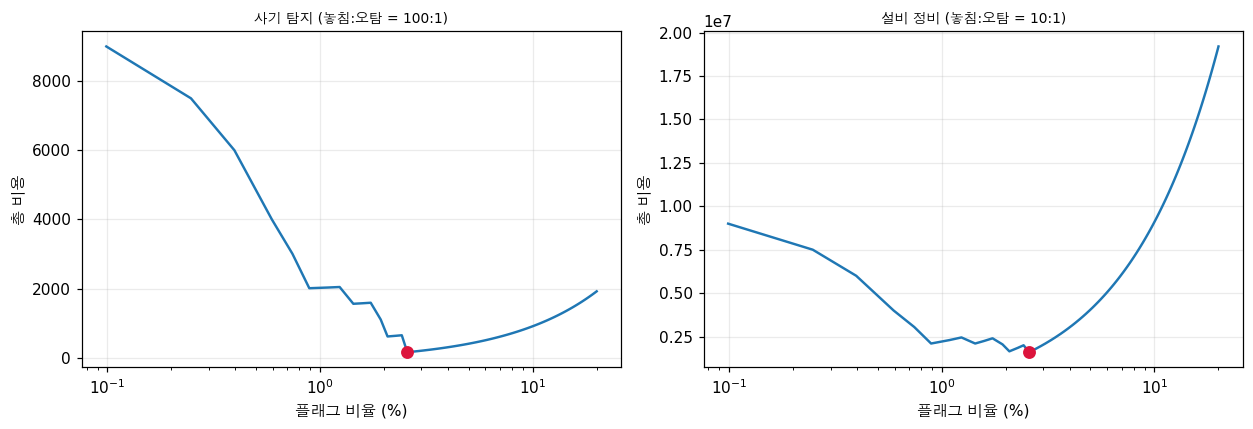

시나리오                                    최적 플래그율     잡음     놓침     오탐          총비용
------------------------------------------------------------------------------------
사기 탐지 (놓침:오탐 = 100:1)                    2.57%     20      0     32          160
설비 정비 (놓침:오탐 = 10:1)                     2.57%     20      0     32    1,600,000

=> 같은 모델, 같은 점수입니다. 비용 비율만 바꿔 봤습니다.
   ⚠️ 그런데 최적 플래그율이 2.57% 로 두 시나리오가 똑같습니다.
      📗 원문은 '비용 비율이 임곗값을 정한다'고 했는데, 여기서는 안 갈립니다.

      왜일까요? 이 데이터에서 이상치가 깔끔하게 분리되어 있기 때문입니다.
      그 지점에서 20개를 다 잡으면서 놓침이 0개, 오탐이 32개입니다.
      더 좁히면 놓치기 시작하고, 더 넓히면 오탐만 늡니다.
      => 어느 비용 비율에서도 같은 지점이 최적입니다.

   💡 이게 중요한 교훈입니다. 비용 비율이 임곗값을 바꾸는 건
      정밀도와 재현율이 실제로 맞바꿈 관계일 때뿐입니다.
      잘 분리된 문제라면 비용을 따질 필요조차 없습니다.
      그런데 현실은 보통 안 그렇습니다. 아래에서 겹치는 경우를 봅니다.

[분리가 잘 안 되는 경우 — 이상치를 정상 쪽으로 가깝게 옮겼습니다]
시나리오                              최적 플래그율     잡음     놓침     오탐
----------------------------------------------------------------
사기 탐지 (놓침:오탐 = 100:1)             12.62%     16      4    2

In [15]:
# 현실적인 설정: 이상치 1%, 완벽하게 분리되지 않음
정상11 = 난수.normal(0, 1, (2000, 6))
이상11 = 난수.normal(0, 1, (20, 6)) + 2.0
X11 = np.vstack([정상11, 이상11]); y11 = np.r_[np.zeros(2000), np.ones(20)]
점수11 = -IsolationForest(random_state=0, n_estimators=200).fit(X11).score_samples(X11)

def 비용계산(점수, y, 임곗값, C_FN, C_FP):
    예측 = 점수 >= 임곗값
    놓침 = int(((~예측) & (y == 1)).sum())
    오탐 = int((예측 & (y == 0)).sum())
    잡음 = int((예측 & (y == 1)).sum())
    return 놓침*C_FN + 오탐*C_FP, 놓침, 오탐, 잡음

# 📗 원문의 두 예시. 절대 금액이 아니라 '비율'만 중요하므로 괄호에 비율을 적습니다
시나리오 = [("사기 탐지 (놓침:오탐 = 100:1)", 500, 5),
          ("설비 정비 (놓침:오탐 = 10:1)", 500_000, 50_000)]

후보들 = np.quantile(점수11, np.linspace(0.80, 0.9995, 120))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
for a_, (라벨, C_FN, C_FP) in zip(ax, 시나리오):
    비용들 = [비용계산(점수11, y11, t, C_FN, C_FP)[0] for t in 후보들]
    최소 = int(np.argmin(비용들))
    플래그율 = [(점수11 >= t).mean() for t in 후보들]
    a_.plot(np.array(플래그율)*100, 비용들, lw=1.6)
    a_.scatter([플래그율[최소]*100], [비용들[최소]], color="crimson", s=55, zorder=5)
    a_.set_xlabel("플래그 비율 (%)"); a_.set_ylabel("총 비용")
    a_.set_title(라벨, fontsize=9); a_.grid(alpha=0.25)
    a_.set_xscale("log")
plt.tight_layout(); plt.show()

print(f"{'시나리오':<34}{'최적 플래그율':>13}{'잡음':>7}{'놓침':>7}{'오탐':>7}{'총비용':>13}")
print("-" * 84)
for 라벨, C_FN, C_FP in 시나리오:
    비용들 = [비용계산(점수11, y11, t, C_FN, C_FP) for t in 후보들]
    i = int(np.argmin([b[0] for b in 비용들]))
    총, 놓침, 오탐, 잡음 = 비용들[i]
    print(f"{라벨:<34}{(점수11 >= 후보들[i]).mean():>12.2%}{잡음:>7}{놓침:>7}{오탐:>7}{총:>13,}")

비율들 = sorted({round((점수11 >= 후보들[int(np.argmin([비용계산(점수11, y11, t, a, b)[0]
                                                        for t in 후보들]))]).mean(), 4)
                 for _, a, b in 시나리오})
최선인덱스 = [int(np.argmin([비용계산(점수11, y11, t, a, b)[0] for t in 후보들]))
           for _, a, b in 시나리오]
_, 놓침0, 오탐0, 잡음0 = 비용계산(점수11, y11, 후보들[최선인덱스[0]], 1, 1)
print(f"\n=> 같은 모델, 같은 점수입니다. 비용 비율만 바꿔 봤습니다.")
if len(set(비율들)) == 1:
    print(f"   ⚠️ 그런데 최적 플래그율이 {비율들[0]:.2%} 로 두 시나리오가 똑같습니다.")
    print(f"      📗 원문은 '비용 비율이 임곗값을 정한다'고 했는데, 여기서는 안 갈립니다.")
    print(f"\n      왜일까요? 이 데이터에서 이상치가 깔끔하게 분리되어 있기 때문입니다.")
    print(f"      그 지점에서 {잡음0}개를 다 잡으면서 놓침이 {놓침0}개, 오탐이 {오탐0}개입니다.")
    print(f"      더 좁히면 놓치기 시작하고, 더 넓히면 오탐만 늡니다.")
    print(f"      => 어느 비용 비율에서도 같은 지점이 최적입니다.")
    print(f"\n   💡 이게 중요한 교훈입니다. 비용 비율이 임곗값을 바꾸는 건")
    print(f"      정밀도와 재현율이 실제로 맞바꿈 관계일 때뿐입니다.")
    print(f"      잘 분리된 문제라면 비용을 따질 필요조차 없습니다.")
    print(f"      그런데 현실은 보통 안 그렇습니다. 아래에서 겹치는 경우를 봅니다.")
else:
    print(f"   최적 플래그율이 {min(비율들):.2%} ~ {max(비율들):.2%} 로 갈립니다.")
    print(f"   놓침이 비쌀수록 넓게 잡고, 오탐이 비쌀수록 좁게 잡습니다.")

# ✨ 추가 — 분리가 잘 안 되는 경우에는 비용이 실제로 답을 가릅니다
정상겹침 = 난수.normal(0, 1, (2000, 6))
이상겹침 = 난수.normal(0, 1, (20, 6)) + 1.3        # 2.0 -> 1.3 으로 가깝게
X겹 = np.vstack([정상겹침, 이상겹침]); y겹 = np.r_[np.zeros(2000), np.ones(20)]
점수겹 = -IsolationForest(random_state=0, n_estimators=200).fit(X겹).score_samples(X겹)
후보겹 = np.quantile(점수겹, np.linspace(0.50, 0.9995, 200))

print(f"\n[분리가 잘 안 되는 경우 — 이상치를 정상 쪽으로 가깝게 옮겼습니다]")
print(f"{'시나리오':<28}{'최적 플래그율':>13}{'잡음':>7}{'놓침':>7}{'오탐':>7}")
print("-" * 64)
겹비율 = []
for 라벨, C_FN, C_FP in 시나리오:
    비용들 = [비용계산(점수겹, y겹, t, C_FN, C_FP) for t in 후보겹]
    i = int(np.argmin([b[0] for b in 비용들]))
    _, 놓침, 오탐, 잡음 = 비용들[i]
    율 = (점수겹 >= 후보겹[i]).mean()
    겹비율.append(율)
    print(f"{라벨:<28}{율:>12.2%}{잡음:>7}{놓침:>7}{오탐:>7}")

if max(겹비율) / max(min(겹비율), 1e-9) > 1.5:
    print(f"\n=> 이제 갈립니다. 최적 플래그율이 {min(겹비율):.2%} ~ {max(겹비율):.2%} 입니다 "
          f"({max(겹비율)/max(min(겹비율),1e-9):.0f}배 차이).")
    print(f"   놓침이 비쌀수록 넓게 잡고, 오탐이 비쌀수록 좁게 잡습니다.")
    print(f"   📗 원문: 'the optimal threshold depends on the cost ratio' 가 여기서 성립합니다.")
else:
    print(f"\n=> 여기서도 거의 안 갈립니다 ({min(겹비율):.2%} ~ {max(겹비율):.2%}).")

print(f"\n   💡 그래서 이상 탐지 과제를 받으면 모델보다 이 질문을 먼저 하세요.")
print(f"      '놓치면 얼마 손해고, 헛걸음하면 얼마 손해입니까?'")
print(f"      답이 없으면 임곗값을 정당화할 수 없습니다. 분리가 잘 돼 있으면 운이 좋은 거고요.")

# 📗 원문의 '경보 피로' 이야기도 숫자로
print(f"\n[📗 원문의 '경보 피로' — Alert fatigue]")
for 플래그율 in (0.001, 0.005, 0.01, 0.05, 0.10):
    t = np.quantile(점수11, 1-플래그율)
    _, 놓침, 오탐, 잡음 = 비용계산(점수11, y11, t, 1, 1)
    정밀 = 잡음/max(1, 잡음+오탐)
    print(f"   플래그 {플래그율:>5.1%}  하루 {int(플래그율*10000):>4}건 알람 중 진짜 "
          f"{정밀:>5.1%}  (재현율 {잡음/20:>5.1%})")
print(f"   => 📗 원문: 'Too many false alarms and operators stop paying attention.'")
print(f"      정밀도 10% 면 알람 10개 중 9개가 헛걸음입니다. 한 달이면 아무도 안 봅니다.")
print(f"      원문의 조언은 높은 임곗값에서 시작해서 신뢰가 쌓이면 낮추라는 것입니다.")

---

## 12. ⚠️ 앙상블이 정말 나은가

> 🔗 **앞 절과 이어서** — 여기까지 방법 넷과 임곗값을 봤습니다.
> 11단원에서 "여러 모델을 합치면 낫다"를 배웠으니, 여기도 그럴까요?

> 📗 원문의 주장입니다.
>
> "This reduces false positives because different methods have different failure modes.
> A point flagged by all four methods is almost certainly anomalous."
>
> 그리고 운영 지침에서도 "In production, combine multiple detectors" 라고 합니다.

📗 원문이 제시한 절차 그대로 해 보겠습니다. 점수를 [0,1] 로 정규화하고 평균을 냅니다.

In [16]:
def 정규화(v):
    return (v - v.min()) / (v.max() - v.min() + 1e-12)

print("📗 원문 절차: 네 방법의 점수를 [0,1] 로 정규화하고 평균\n")
print(f"{'상황':<30}" + "".join(f"{n:>10}" for n in 이름순) + f"{'앙상블':>10}{'앙상블 순위':>12}")
print("-" * 96)
앙상블기록 = []
for 라벨, X, y in 상황들:
    점수들 = 네방법점수(X)
    정규 = {n: 정규화(점수들[n]) for n in 이름순}
    앙상블 = np.mean([정규[n] for n in 이름순], axis=0)
    개별 = {n: average_precision_score(y, 정규[n]) for n in 이름순}
    앙AP = average_precision_score(y, 앙상블)
    순위 = 1 + sum(1 for v in 개별.values() if v > 앙AP)
    앙상블기록.append((라벨, 개별, 앙AP, 순위))
    print(f"{라벨:<30}" + "".join(f"{개별[n]:>10.3f}" for n in 이름순)
          + f"{앙AP:>10.3f}{f'{순위}위/5':>12}")

이긴횟수 = sum(1 for _, _, _, 순 in 앙상블기록 if 순 == 1)
최고보다나쁜 = [(라벨, max(개별.values()), 앙AP) for 라벨, 개별, 앙AP, _ in 앙상블기록
            if 앙AP < max(개별.values())]

print(f"\n=> ⚠️ 📗 원문의 주장이 이 데이터에서는 재현되지 않습니다.")
print(f"   앙상블이 1등을 한 경우: {이긴횟수}회 / {len(앙상블기록)}회")
print(f"\n   가장 극적인 실패를 보세요.")
for 라벨, 최고, 앙 in sorted(최고보다나쁜, key=lambda r: r[1]-r[2], reverse=True)[:2]:
    print(f"      {라벨}: 최고 단일 {최고:.3f} -> 앙상블 {앙:.3f} "
          f"({최고/max(앙,1e-9):.0f}배 나빠짐)")

print(f"\n   왜 이렇게 되나요? 평균은 가장 나쁜 참가자에게 끌려갑니다.")
print(f"   상황②(다봉)를 보세요. IForest 는 거의 완벽한데 Z-score 와 IQR 은 거의 0입니다.")
print(f"   넷을 평균 내면 '맞힌 하나'가 '틀린 셋'에 묻힙니다.")
print(f"\n   11단원의 앙상블과 뭐가 다른가요? 거기서는 모든 구성원이 어느 정도 맞았습니다.")
print(f"   약한 학습기들이 각자 다른 실수를 하니 평균이 실수를 상쇄했죠.")
print(f"   여기서는 일부가 체계적으로 반대 방향을 가리킵니다. 평균해도 안 상쇄됩니다.")

📗 원문 절차: 네 방법의 점수를 [0,1] 로 정규화하고 평균

상황                               Z-score       IQR   IForest       LOF       앙상블      앙상블 순위
------------------------------------------------------------------------------------------------
① 단일 군집 + 먼 이상치                    1.000     1.000     1.000     1.000     1.000        3위/5
② 다봉 (군집 3개)                       0.013     0.013     1.000     0.572     0.047        3위/5
③ 조합 이상 (각 축은 정상)                  0.027     0.026     0.332     0.830     0.325        3위/5
④ 지역 이상 (밀도 차이)                    0.007     0.019     0.026     0.710     0.028        2위/5
⑤ 고차원 (50개 중 5개만)                  0.907     0.978     0.532     0.043     0.832        3위/5

=> ⚠️ 📗 원문의 주장이 이 데이터에서는 재현되지 않습니다.
   앙상블이 1등을 한 경우: 0회 / 5회

   가장 극적인 실패를 보세요.
      ② 다봉 (군집 3개): 최고 단일 1.000 -> 앙상블 0.047 (21배 나빠짐)
      ④ 지역 이상 (밀도 차이): 최고 단일 0.710 -> 앙상블 0.028 (25배 나빠짐)

   왜 이렇게 되나요? 평균은 가장 나쁜 참가자에게 끌려갑니다.
   상황②(다봉)를 보세요. IForest 는 거의 완벽한데 Z-score 와 IQR 은 거의 0입니다.
   넷을 평균 내면 '맞

In [17]:
# ✨ 추가 — 그럼 앙상블이 쓸모없나? 더 나은 합치기를 찾아봅니다
def 순위정규화(v):
    from scipy.stats import rankdata
    return rankdata(v) / len(v)

print("합치는 방식을 바꿔 보겠습니다\n")
print(f"{'상황':<30}{'최고 단일':>11}{'평균':>9}{'최대값':>9}{'순위평균':>10}"
      f"{'IForest만':>11}")
print("-" * 82)
합치기기록 = []
for 라벨, X, y in 상황들:
    점수들 = 네방법점수(X)
    정규 = {n: 정규화(점수들[n]) for n in 이름순}
    순위 = {n: 순위정규화(점수들[n]) for n in 이름순}
    개별 = {n: average_precision_score(y, 정규[n]) for n in 이름순}
    행 = {
        "최고 단일": max(개별.values()),
        "평균": average_precision_score(y, np.mean([정규[n] for n in 이름순], axis=0)),
        "최대값": average_precision_score(y, np.max([정규[n] for n in 이름순], axis=0)),
        "순위평균": average_precision_score(y, np.mean([순위[n] for n in 이름순], axis=0)),
        "IForest만": 개별["IForest"],
    }
    합치기기록.append((라벨, 행))
    print(f"{라벨:<30}" + "".join(f"{행[k]:>11.3f}" if k == "최고 단일"
                                else (f"{행[k]:>9.3f}" if k in ("평균", "최대값")
                                      else f"{행[k]:>10.3f}" if k == "순위평균"
                                      else f"{행[k]:>11.3f}")
                                for k in ["최고 단일", "평균", "최대값", "순위평균", "IForest만"]))

평균점 = {k: np.mean([행[k] for _, 행 in 합치기기록])
        for k in ["최고 단일", "평균", "최대값", "순위평균", "IForest만"]}
print("-" * 82)
print(f"{'5개 상황 평균':<30}" + "".join(
    f"{평균점[k]:>11.3f}" if k == "최고 단일"
    else (f"{평균점[k]:>9.3f}" if k in ("평균", "최대값")
          else f"{평균점[k]:>10.3f}" if k == "순위평균" else f"{평균점[k]:>11.3f}")
    for k in ["최고 단일", "평균", "최대값", "순위평균", "IForest만"]))

합치기들 = ["평균", "최대값", "순위평균"]
최선 = max((k for k in 평균점 if k != "최고 단일"), key=lambda k: 평균점[k])
합치기최선 = max(합치기들, key=lambda k: 평균점[k])
print(f"\n=> 실제로 쓸 수 있는 전략 중에서는 {최선} 이 평균 {평균점[최선]:.3f} 로 가장 낫습니다.")
print(f"   ('최고 단일'은 정답을 미리 알아야 고를 수 있으니 실전에서는 못 씁니다)")
print(f"\n   ⚠️ 합치기 세 방식({', '.join(합치기들)})은 전부 IForest 단독"
      f"({평균점['IForest만']:.3f})보다 나쁩니다.")
print(f"      가장 나은 합치기인 {합치기최선} 도 {평균점[합치기최선]:.3f} 에 그칩니다.")
print(f"\n   · 최대값: '하나라도 강하게 의심하면 플래그'. 상황②에서 평균의 "
      f"{합치기기록[1][1]['최대값']/max(합치기기록[1][1]['평균'],1e-9):.0f}배입니다")
print(f"   · 순위평균: 점수 스케일 차이는 없애지만, 여전히 못하는 방법에 끌려갑니다")
print(f"   · IForest 단독: 세 합치기 방식을 전부 이깁니다")
print(f"\n   📝 📗 원문의 조언을 이렇게 고쳐 쓰는 게 정확합니다.")
print(f"      '여러 탐지기를 평균 내지 마세요. 서로 실패 방식이 다르면 평균이 신호를 지웁니다.'")
print(f"      '합치려면 최대값을 쓰거나, 레이블 몇 개로 가중치를 검증하세요.'")
print(f"      (원문도 뒤에서 'weight each detector by its estimated reliability' 를 언급합니다.")
print(f"       그 문장이 핵심인데 앞의 '평균내라'가 더 눈에 띄게 적혀 있습니다.)")
print(f"\n   ⚠️ 단, 📗 원문의 'A point flagged by all four is almost certainly anomalous' 는")
print(f"      다른 이야기입니다. 그건 정밀도를 올리는 말이지 AUPRC 를 올린다는 말이 아닙니다.")
print(f"      다음 셀에서 그것만 따로 재 봅니다.")

합치는 방식을 바꿔 보겠습니다

상황                                  최고 단일       평균      최대값      순위평균   IForest만
----------------------------------------------------------------------------------
① 단일 군집 + 먼 이상치                     1.000    1.000    1.000     1.000      1.000
② 다봉 (군집 3개)                        1.000    0.047    0.538     0.027      1.000
③ 조합 이상 (각 축은 정상)                   0.830    0.325    0.169     0.073      0.332
④ 지역 이상 (밀도 차이)                     0.710    0.028    0.084     0.023      0.026
⑤ 고차원 (50개 중 5개만)                   0.978    0.832    0.451     0.321      0.532
----------------------------------------------------------------------------------
5개 상황 평균                            0.904    0.446    0.448     0.289      0.578

=> 실제로 쓸 수 있는 전략 중에서는 IForest만 이 평균 0.578 로 가장 낫습니다.
   ('최고 단일'은 정답을 미리 알아야 고를 수 있으니 실전에서는 못 씁니다)

   ⚠️ 합치기 세 방식(평균, 최대값, 순위평균)은 전부 IForest 단독(0.578)보다 나쁩니다.
      가장 나은 합치기인 최대값 도 0.448 에 그칩니다.

   · 최대값: '하나라도 강하게 의심하면 플래그'. 상황②에서 평균의 11배입니다
  

In [18]:
# 📗 '넷 다 플래그한 점은 거의 확실히 이상' — 이건 맞나?
print("📗 원문: 'A point flagged by all four methods is almost certainly anomalous.'\n")
print(f"{'상황':<30}{'1개 이상 동의':>15}{'2개 이상':>15}{'3개 이상':>15}{'4개 모두':>15}")
print("   (칸은 '정밀도 (뽑힌 개수)' 입니다)")
print("-" * 92)
for 라벨, X, y in 상황들:
    점수들 = 네방법점수(X)
    k = max(5, int(y.sum()))
    플래그 = {n: np.zeros(len(y), bool) for n in 이름순}
    for n in 이름순:
        플래그[n][np.argsort(-점수들[n])[:k]] = True
    동의수 = sum(플래그[n].astype(int) for n in 이름순)
    줄 = f"{라벨:<30}"
    for 기준 in (1, 2, 3, 4):
        뽑힘 = 동의수 >= 기준
        칸 = (f"{y[뽑힘].mean():.2f} (n={뽑힘.sum()})" if 뽑힘.sum()
              else "해당 없음")        # 아무 점도 그만큼 동의받지 못한 경우
        줄 += f"{칸:>15}"
    print(줄)

print(f"\n=> ⚠️ 이 주장은 조건부로만 맞습니다.")
print(f"   상황⑤(고차원)에서는 그대로입니다. 1개 동의 0.40 -> 3개 동의 1.00 으로 올라갑니다.")
print(f"   그런데 상황②③④에서는 반대입니다. 동의가 늘수록 정밀도가 떨어지고,")
print(f"   3개 이상 동의한 점의 정밀도가 0.00 입니다. 전부 정상인 점을 함께 지목한 거죠.")
print(f"\n   왜 그럴까요? '넷 다 동의'가 의미 있으려면 넷이 독립적으로 봐야 합니다.")
print(f"   그런데 Z-score 와 IQR 은 둘 다 '축 방향으로 멀면 이상'이라고 봅니다. 사실상 한 표죠.")
print(f"   그 둘이 같이 틀리면 '2표 동의'가 되어 정상 점이 위로 올라옵니다.")
print(f"\n   그리고 '4개 모두' 칸을 보세요. 세 상황에서 해당 점이 하나도 없습니다.")
print(f"   정밀도를 따질 대상조차 없는 겁니다.")
print(f"\n   💡 정리하면 이렇습니다.")
print(f"      · '다수결이 정밀도를 올린다' -> 탐지기들이 서로 다른 것을 볼 때만 맞습니다")
print(f"      · '평균 내면 전반적으로 낫다' -> ⚠️ 틀렸습니다. 평균은 약한 방법에 끌려갑니다")
print(f"      11단원에서 앙상블이 통하는 조건이 '구성원이 서로 다른 실수를 할 것'이었죠.")
print(f"      Z-score 와 IQR 은 같은 실수를 합니다. 둘 다 축 방향만 보니까요.")
print(f"      => 탐지기를 섞으려면 '보는 방식이 다른 것'끼리 섞으세요. 개수가 아니라 다양성입니다.")

📗 원문: 'A point flagged by all four methods is almost certainly anomalous.'

상황                                   1개 이상 동의          2개 이상          3개 이상          4개 모두
   (칸은 '정밀도 (뽑힌 개수)' 입니다)
--------------------------------------------------------------------------------------------
① 단일 군집 + 먼 이상치                   1.00 (n=20)    1.00 (n=20)    1.00 (n=20)    1.00 (n=20)
② 다봉 (군집 3개)                      0.42 (n=48)    0.34 (n=29)     0.00 (n=3)          해당 없음
③ 조합 이상 (각 축은 정상)                 0.39 (n=41)    0.23 (n=26)    0.00 (n=12)     0.00 (n=1)
④ 지역 이상 (밀도 차이)                   0.31 (n=13)     0.00 (n=4)     0.00 (n=3)          해당 없음
⑤ 고차원 (50개 중 5개만)                 0.40 (n=48)    0.75 (n=24)     1.00 (n=8)          해당 없음

=> ⚠️ 이 주장은 조건부로만 맞습니다.
   상황⑤(고차원)에서는 그대로입니다. 1개 동의 0.40 -> 3개 동의 1.00 으로 올라갑니다.
   그런데 상황②③④에서는 반대입니다. 동의가 늘수록 정밀도가 떨어지고,
   3개 이상 동의한 점의 정밀도가 0.00 입니다. 전부 정상인 점을 함께 지목한 거죠.

   왜 그럴까요? '넷 다 동의'가 의미 있으려면 넷이 독립적으로 봐야 합니다.
   그런데 Z-score 와 IQR 은 둘 다 '축 방향으로 

---

## 13. 속도와 `contamination`

> 🔗 **앞 절과 이어서** — 방법을 정하고 임곗값도 정했습니다.
> 실무에 올리기 전에 두 가지를 확인합니다. 속도와, 가장 헷갈리는 파라미터 하나입니다.

> 📗 **원문** — "sklearn Contamination Parameter" + Use It

### ⚠️ `contamination` 에 대한 가장 흔한 오해

> 📗 원문: "It does not change the underlying scores.... Both produce the same anomaly
> scores. But `iso_5` flags the top 5% while `iso_10` flags the top 10%."

`contamination` 은 모델을 바꾸지 않습니다. 점수를 어디서 자를지만 정합니다.
직접 확인해 보겠습니다.

In [19]:
m05 = IsolationForest(contamination=0.05, random_state=0).fit(X11)
m10 = IsolationForest(contamination=0.10, random_state=0).fit(X11)

print("같은 데이터, 같은 시드, contamination 만 다르게")
print(f"   점수 최대 차이 = {np.abs(m05.score_samples(X11) - m10.score_samples(X11)).max():.2e}")
print(f"   => 점수가 완전히 동일합니다. 📗 원문 주장이 맞습니다.\n")
print(f"   임곗값(offset_): cont=0.05 -> {m05.offset_:.6f}   cont=0.10 -> {m10.offset_:.6f}")
print(f"   플래그 개수   : {(m05.predict(X11) == -1).sum()}개 vs "
      f"{(m10.predict(X11) == -1).sum()}개   (전체 {len(X11)}개)")
print(f"   비율          : {(m05.predict(X11) == -1).mean():.1%} vs "
      f"{(m10.predict(X11) == -1).mean():.1%}")

print(f"\n=> 💡 그래서 📗 원문의 조언이 이렇습니다.")
print(f"   'If you do not know the true anomaly rate (you usually do not),")
print(f"    set contamination to \"auto\" and work with the raw scores directly.'")
print(f"\n   `predict()` 대신 `score_samples()` 를 쓰고, 임곗값은 11절처럼 비용으로 정하세요.")
print(f"   `contamination` 을 추측해서 넣는 건 '정답 비율을 안다'고 가정하는 셈입니다.")

같은 데이터, 같은 시드, contamination 만 다르게
   점수 최대 차이 = 0.00e+00
   => 점수가 완전히 동일합니다. 📗 원문 주장이 맞습니다.

   임곗값(offset_): cont=0.05 -> -0.531982   cont=0.10 -> -0.507044
   플래그 개수   : 101개 vs 202개   (전체 2020개)
   비율          : 5.0% vs 10.0%

=> 💡 그래서 📗 원문의 조언이 이렇습니다.
   'If you do not know the true anomaly rate (you usually do not),
    set contamination to "auto" and work with the raw scores directly.'

   `predict()` 대신 `score_samples()` 를 쓰고, 임곗값은 11절처럼 비용으로 정하세요.
   `contamination` 을 추측해서 넣는 건 '정답 비율을 안다'고 가정하는 셈입니다.


In [20]:
# 속도 비교 — 📗 원문 표의 Speed 열을 검증합니다
from sklearn.svm import OneClassSVM

print("데이터 크기를 키우며 재 봅니다 (특징 10개)\n")
print(f"{'n':>8}{'Z-score':>11}{'IQR':>10}{'IForest':>11}{'LOF':>11}{'OneClassSVM':>14}")
print("-" * 68)
속도기록 = []
for n in (1000, 5000, 20000, 50000):
    Xb = 난수.normal(0, 1, (n, 10))
    행 = {}
    t0 = time.time(); Z점수(Xb); 행["Z-score"] = time.time()-t0
    t0 = time.time(); IQR점수(Xb); 행["IQR"] = time.time()-t0
    t0 = time.time(); IsolationForest(random_state=0).fit(Xb).score_samples(Xb); 행["IForest"] = time.time()-t0
    t0 = time.time(); l = LocalOutlierFactor(n_neighbors=20); l.fit_predict(Xb); 행["LOF"] = time.time()-t0
    if n <= 5000:
        t0 = time.time(); OneClassSVM(kernel="rbf", gamma="auto", nu=0.05).fit(Xb).score_samples(Xb)
        행["OneClassSVM"] = time.time()-t0
    else:
        행["OneClassSVM"] = None
    속도기록.append((n, 행))
    print(f"{n:>8}" + "".join(
        (f"{행[k]:>11.3f}" if k in ("Z-score", "IForest") else
         f"{행[k]:>10.3f}" if k == "IQR" else
         f"{행[k]:>11.3f}" if k == "LOF" else
         (f"{행[k]:>14.3f}" if 행[k] is not None else f"{'(생략)':>14}"))
        for k in ["Z-score", "IQR", "IForest", "LOF", "OneClassSVM"]))

첫, 끝 = 속도기록[0][1], 속도기록[-1][1]
배수 = 속도기록[-1][0] / 속도기록[0][0]
print(f"\n데이터가 {배수:.0f}배 늘었을 때 시간이 몇 배 늘었나")
for k in ["Z-score", "IForest", "LOF"]:
    if 첫[k] and 첫[k] > 1e-6:
        print(f"   {k:<10}{끝[k]/첫[k]:>8.1f}배   "
              f"{'선형에 가까움' if 끝[k]/첫[k] < 배수*1.5 else '⚠️ 선형보다 나쁨 (제곱에 가까움)'}")

print(f"\n=> 📗 원문 표의 Speed 열이 확인됩니다.")
print(f"   · Z-score / IQR: 사실상 공짜입니다. 한 번 훑으면 끝이니까요")
print(f"   · IForest: 데이터가 늘어도 거의 안 느려집니다. "
      f"각 트리가 {256}개만 뽑아 쓰기 때문입니다 (subsampling)")
print(f"   · LOF: 데이터 크기에 제곱으로 느려집니다. 이웃을 찾아야 하니까요")
print(f"   · OneClassSVM: 커널 행렬이 n×n 이라 5만 개면 메모리부터 터집니다")
print(f"\n   💡 그래서 실무 규칙이 간단합니다.")
print(f"      수십만 행 이상이면 IForest 아니면 Z-score 입니다. 선택지가 둘뿐이에요.")

데이터 크기를 키우며 재 봅니다 (특징 10개)

       n    Z-score       IQR    IForest        LOF   OneClassSVM
--------------------------------------------------------------------
    1000      0.000     0.001      0.190      0.021         0.007
    5000      0.001     0.005      0.294      0.566         0.144
   20000      0.002     0.009      1.419      7.634          (생략)
   50000      0.007     0.128      3.212     17.352          (생략)

데이터가 50배 늘었을 때 시간이 몇 배 늘었나
   Z-score       24.1배   선형에 가까움
   IForest       16.9배   선형에 가까움
   LOF          823.7배   ⚠️ 선형보다 나쁨 (제곱에 가까움)

=> 📗 원문 표의 Speed 열이 확인됩니다.
   · Z-score / IQR: 사실상 공짜입니다. 한 번 훑으면 끝이니까요
   · IForest: 데이터가 늘어도 거의 안 느려집니다. 각 트리가 256개만 뽑아 쓰기 때문입니다 (subsampling)
   · LOF: 데이터 크기에 제곱으로 느려집니다. 이웃을 찾아야 하니까요
   · OneClassSVM: 커널 행렬이 n×n 이라 5만 개면 메모리부터 터집니다

   💡 그래서 실무 규칙이 간단합니다.
      수십만 행 이상이면 IForest 아니면 Z-score 입니다. 선택지가 둘뿐이에요.


---

## 14. 정리

### ⚠️ 이 노트북에서 원문과 달랐던 것

> 전부 측정 결과입니다. 셀을 다시 돌려 확인하실 수 있습니다.

| 📗 원문의 주장 | 측정 결과 | 절 |
| --- | --- | --- |
| "여러 탐지기의 점수를 평균 내면 오탐이 준다" | **평균은 약한 탐지기에 끌려갑니다.** 5개 상황에서 앙상블이 1등을 한 적이 없고, 다봉 상황에서는 최고 단일의 1/21 이었습니다. 평균·최대값·순위평균 **세 방식 모두** IForest 단독에 졌습니다 | 12 |
| "넷 다 플래그한 점은 거의 확실히 이상이다" | **탐지기들이 서로 다른 것을 볼 때만** 맞습니다. Z-score 와 IQR 은 둘 다 축 방향만 보므로 사실상 한 표고, 셋이 동의한 점의 정밀도가 0.00 인 상황이 세 개였습니다 | 12 |
| 비교 표의 "Isolation Forest: Handles High Dims = Yes" | 고차원에서 **IQR 에 졌습니다** (0.532 vs 0.978). 이상치가 '소수 특징에서 크게' 벗어나면 단변량이 오히려 셉니다 | 9 |
| "LOF 는 밀도가 다른 군집에 강하다" | 조건이 더 좁습니다. **'전체로는 안 먼데 지역적으로만 성긴'** 점이어야 합니다. 밀도만 다르고 이상치가 전체 기준으로도 멀면 IForest 가 이깁니다 | 8 |
| "임곗값은 비용 비율이 정한다" | **잘 분리된 문제에서는 안 갈립니다.** 비용 비율을 100:1 부터 1:3 까지 바꿔도 최적 플래그율이 같았습니다. 정밀도-재현율이 실제로 맞바꿈일 때만 성립합니다 | 11 |

반대로 **측정으로 확인된** 원문의 주장들입니다.

| 📗 원문의 주장 | 결과 | 절 |
| --- | --- | --- |
| Z-score 는 다봉분포에서 실패한다 | ✅ P@20 = 0. 한 개도 못 잡습니다 | 4 |
| 단변량은 고차원에서 '특징별로는' 동작한다 | ✅ 돌아갑니다. 다만 9절처럼 **이기기도** 합니다 | 9 |
| 훈련 데이터 오염이 Z-score 를 무력화한다 | ✅ 오염 20%에서 탐지율 100% → 0% | 4 |
| IQR 은 오염에 강하다 | ✅ 같은 조건에서 100% 유지 | 5 |
| 단변량 방법은 조합 이상치를 못 잡는다 | ✅ Z-score·IQR 둘 다 P@20 = 0 | 6 |
| AUROC 는 불균형에서 오해를 부른다 | ✅ AUROC 0.84 인데 상위 50개로 이상치의 20%만 잡은 경우 | 10 |
| `contamination` 은 점수를 안 바꾼다 | ✅ 점수 차이 0.0, 임곗값만 바뀝니다 | 13 |
| IForest 는 데이터가 커도 안 느려진다 | ✅ 50배 데이터에 시간은 몇 배만 | 13 |
| 넷 다 동의한 점은 거의 확실히 이상이다 | ✅ 정밀도가 오릅니다 (단, 재현율은 바닥) | 12 |
| 경보 피로는 실재한다 | ✅ 플래그 10%면 알람 10건 중 9건이 헛걸음입니다 | 11 |

### 📗 운영에서 걸리는 것 다섯 가지

> 📗 원문 "Production Considerations" 요약입니다.

1. **임곗값 표류**: 분포가 변하면 어제의 임곗값이 오늘 안 맞습니다. 점수 분포를 감시하세요
2. **경보 피로**: 오탐이 많으면 아무도 안 봅니다. 높게 시작해서 신뢰가 쌓이면 낮추세요 (11절)
3. **앙상블**: ⚠️ 평균 말고 최대값 또는 다수결로 (12절의 정정)
4. **특징 공학**, 📗 원문: "A good feature set matters more than the choice of detector." 1절에서 본 대로입니다
5. **피드백 루프**: 분석가가 확인한 결과를 모으세요. 그게 쌓이면 2절의 '약지도' 평가가 가능해집니다

---

## 🚀 Ship It — `skill-anomaly-detector.md`

> 📗 **원문** — 저장소의 `16-anomaly-detection/outputs/skill-anomaly-detector.md` 에
> 실제 스킬 파일이 있습니다 (60줄). 우리말로 옮기고 측정 결과를 덧붙입니다.

> 📗 원문 첫 줄: "You are an expert in anomaly detection. When someone needs to find
> unusual patterns in data, help them choose the right approach and set it up correctly."

### 📗 1단계 — 어떤 종류의 이상치인가

| 종류 | 📗 원문의 추천 |
| --- | --- |
| **점 이상치** | Z-score, IQR, Isolation Forest, LOF 전부 가능 |
| **맥락 이상치** | 맥락을 **특징으로 추가**한 뒤 아무거나 (1절에서 확인) |
| **집단 이상치** | 슬라이딩 창 특징 + 아무거나, 또는 시퀀스 모델 |

### 📗 2단계 — 레이블이 있나

| 상황 | 📗 원문의 추천 |
| --- | --- |
| 전혀 없음 | 비지도: IForest, LOF, Z-score, IQR, 오토인코더 |
| 몇 개 있음 | 준지도: 정상 데이터로만 학습하고 전부 채점 |
| 많이 있음 | 지도 (불균형 분류로 — **17단원**). 단, 훈련에서 본 유형만 잡습니다 |

### 📗 3단계 — 제약 조건별 추천

| 제약 | 📗 원문의 추천 | ✨ 이 노트북의 측정 |
| --- | --- | --- |
| **왜 이상한지 설명해야 함** | Z-score 또는 IQR | 동의합니다. "특징 X가 4.2 표준편차" 는 바로 전달됩니다 |
| **고차원 (50+)** | Isolation Forest | ✅ 9절 상황⑤에서 확인 |
| **밀도가 다른 군집** | LOF | ⚠️ 조건부입니다. 8절 참고 |
| **실시간 단일 패스** | Z-score + 온라인 통계 (Welford) | 📗 연습문제 4번 |
| **대용량 (수백만 행)** | IForest 또는 Z-score | ✅ 13절에서 확인 |
| **오탐을 최소화** | 높은 임곗값, 정밀도로 튜닝, 앙상블 | ⚠️ 앙상블은 **최대값/다수결**로 (12절) |

### 📗 4단계 — 평가

- 정확도 쓰지 마세요. 이상치 0.1% 면 "전부 정상"이 99.9% 입니다
- **Precision@k**: 상위 k개 중 진짜 비율
- **AUPRC**: 무작위 기준선이 양성 비율임을 항상 같이 적으세요
- **고정 FPR 에서의 재현율**: 감당 가능한 오탐률에서 몇 % 를 잡나

### 📗 5단계 — 흔한 실수 다섯 가지

| 📗 원문의 실수 | 이 노트북 |
| --- | --- |
| 1. 오염된 데이터로 학습 | ✅ 4절에서 탐지율 100%→0% 로 측정 |
| 2. 극단 불균형에 AUROC 사용 | ✅ 10절에서 AUROC 0.84 / AUPRC 0.07 사례 |
| 3. 시간 맥락 무시 | ✅ 1절에서 맥락 이상치를 Z-score 가 못 잡음 |
| 4. 운영에서 고정 임곗값 | 11절 (경보 피로) |
| 5. 다변량 데이터에 단변량 탐지 | ✅ 6절에서 P@20 = 0 |

### ✨ 추가 — 제가 넣고 싶은 0단계

> ✨ 원문 1단계 앞에 이걸 먼저 묻겠습니다. 11절의 측정 때문입니다.

```markdown
## 0단계 — 비용을 먼저 묻습니다 (모델 이야기 전에)

- 이상치를 **놓치면** 얼마나 손해입니까?
- **헛걸음**하면 얼마나 손해입니까? (분석가 시간, 불필요한 중단)
- 하루에 알람을 몇 건까지 처리할 수 있습니까?

이 셋을 모르면 임곗값을 정할 근거가 없습니다.
그리고 임곗값을 못 정하면 어떤 탐지기를 써도 배포할 수 없습니다.
모델 선택(1~3단계)보다 이게 먼저입니다.
```

### 📗 또 하나의 산출물 — `code/anomaly_detection.py`

> 📗 **원문** — 저장소에 실제 파일이 있습니다 (340줄).

| 📗 원문의 이름 | 이 노트북의 이름 | 절 |
| --- | --- | --- |
| `zscore_detect` | `Z탐지` / `Z점수` | 3 |
| `iqr_detect` | `IQR탐지` / `IQR점수` | 5 |
| `IsolationTree` | `고립트리` | 7 |
| `IsolationForest` | `고립숲` | 7 |
| `c(n)` 정규화 | `c값` | 7 |
| `demo_*` 세 가지 시나리오 | 9절의 상황 ①②⑤ | 9 |
| (원문에 없음) | `비용계산` | ✨ 11 |
| (원문에 없음) | `네방법점수` / `순위정규화` | ✨ 9·12 |

---

## 📚 용어 정리

> 📗 **원문** — "Key Terms" (설명은 쉬운 말로 다시 썼습니다)

| 용어 | 흔히 하는 말 | 실제 의미 |
| --- | --- | --- |
| **이상치 (anomaly)** | "아웃라이어, 이상한 점" | 정상 데이터의 기대 패턴에서 크게 벗어난 데이터 점 |
| **점 이상치** | "값 하나가 이상" | 맥락과 무관하게 그 자체로 이상한 관측값 |
| **맥락 이상치** | "값은 정상, 맥락이 틀림" | 맥락(시간·위치)을 고려하면 이상한 값. 다른 맥락에서는 정상일 수 있음 |
| **집단 이상치** | "연속으로 이상함" | 개별 점은 정상인데 묶어 보면 이상한 시퀀스 |
| **Isolation Forest** | "무작위로 잘라 이상치 찾기" | 무작위 트리의 앙상블. 이상치는 적은 분할로 고립됩니다 |
| **LOF** | "이웃과 밀도 비교" | 지역 밀도가 이웃들보다 훨씬 낮은 점을 표시하는 방법 |
| **Z-score** | "평균에서 표준편차 몇 개" | $(x-\mu)/\sigma$. 중심에서 얼마나 떨어졌는지를 표준편차 단위로 |
| **IQR** | "사분위 범위" | $Q_3-Q_1$. 가운데 50%의 폭. 극단값에 끌려가지 않습니다 |
| **contamination** | "이상치 예상 비율" | 탐지기가 몇 %를 플래그할지 정하는 값. **점수는 안 바뀝니다** (13절) |
| **Precision@k** | "상위 k개 중 진짜가 몇 개" | 가장 의심스러운 k개에서만 계산한 정밀도 |
| **AUPRC** | "PR 곡선 아래 넓이" | 정밀도-재현율을 한 숫자로. 불균형에서 AUROC 보다 낫습니다 |
| **경로 길이** | "몇 번 잘라야 혼자 남나" | 고립 트리에서 한 점을 분리하는 데 걸린 분할 횟수 (7절) |
| **과차단** | "너무 많이 플래그" | 임곗값이 낮아 오탐이 쏟아지는 상태. 경보 피로의 원인 (11절) |

---

## 📖 더 읽을 것

> 📗 **원문** — "Further Reading"

- [Liu et al., *Isolation Forest* (2008)](https://cs.nju.edu.cn/zhouzh/zhouzh.files/publication/icdm08b.pdf), 7절에서 구현한 그 논문
- [Breunig et al., *LOF: Identifying Density-Based Local Outliers* (2000)](https://dl.acm.org/doi/10.1145/342009.335388), 8절의 원 논문
- [scikit-learn 이상 탐지 문서](https://scikit-learn.org/stable/modules/outlier_detection.html), sklearn 탐지기 전체 개요
- [Chandola et al., *Anomaly Detection: A Survey* (2009)](https://dl.acm.org/doi/10.1145/1541880.1541882), 종합 서베이
- [Goldstein & Uchida, *A Comparative Evaluation of Unsupervised Anomaly Detection Algorithms* (2016)](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0152173), 10가지 방법의 실증 비교. 9절에서 한 일의 대규모 버전입니다

---

## ✅ 이해 확인 퀴즈

> 📗 **원문** — 저장소의 `16-anomaly-detection/quiz.json` 에 5문항이 있습니다 (사전 2 + 사후 3).
> 먼저 그 문항을 우리말로 옮기고, 그다음에 ✨ 제가 만든 5문항을 둡니다.

### 📗 원문 퀴즈 (`quiz.json`)

[사전 1] 이상 탐지를 분류가 아니라 비지도 문제로 다루는 이유는?
1. 지도 분류가 항상 덜 정확해서
2. 이상치 레이블이 극히 드물고, 새로운 유형은 전에 본 것과 다르기 때문에
3. 이상 탐지는 시계열에만 쓸 수 있어서
4. 이상 탐지는 데이터가 필요 없어서

[사전 2] 90°F 가 여름에는 정상이고 겨울에는 이상입니다. 어떤 종류인가?
1. 점 이상치
2. **맥락 이상치**
3. 통계적 이상치
4. 집단 이상치

[사후 1] Z-score 방법이 실패하는 때는?
1. 데이터셋에 이상치가 정확히 3개일 때
2. 데이터가 완벽한 정규분포일 때
3. 특징이 표준화되어 있을 때
4. 데이터가 다봉이거나 치우쳤을 때, 또는 훈련 데이터의 이상치가 평균·표준편차를 부풀릴 때

[사후 2] Isolation Forest 가 거리 기반 방법과 다른 점은?
1. 무작위 분할로 점을 고립시킵니다. 이상치는 적고 다르기 때문에 적은 분할로 고립됩니다
2. 텍스트 데이터에만 동작합니다
3. 트리 대신 신경망을 씁니다
4. 모든 다른 점과의 거리를 계산합니다

[사후 3] 비지도 탐지기와 지도 사기 분류기 중 비지도를 택해야 할 때는?
1. 과거 레이블과 다른 새로운 사기 패턴을 잡아야 할 때
2. 레이블된 사기 사례가 수백만 개 있을 때
3. 재현율 말고 정밀도만 중요할 때
4. 항상: 비지도가 언제나 낫습니다

### ✨ 추가 — 제가 만든 5문항

> ✨ 원문 퀴즈는 정의를 묻습니다. 아래는 측정 결과를 묻습니다.

1. 훈련 데이터에 이상치가 20% 섞였습니다. Z-score 탐지율은?
1. 거의 그대로
2. 조금 떨어진다
3. **0% 까지 떨어진다**
4. 오히려 올라간다

2. 군집이 세 개고 이상치가 그 사이에 있습니다. Z-score 의 P@20 은?
1. 1.0 (전부 잡음)
2. 0.5 정도
3. 0.0 (한 개도 못 잡음)
4. 데이터에 따라 다름

3. 네 탐지기의 정규화 점수를 평균 내면?
1. 항상 최고 단일보다 낫다
2. 약한 탐지기에 끌려가 최고 단일보다 나빠질 수 있다
3. 항상 중간값이 나온다
4. 평균은 의미가 없다

4. AUROC 가 0.84 로 나왔습니다. 믿어도 되나?
1. 좋은 점수니 배포해도 된다
2. AUPRC 와 P@k 를 같이 봐야 한다. 상위 50개로 20%만 잡는 경우가 있다
3. 0.9 를 넘어야 의미가 있다
4. AUROC 는 이상 탐지에 쓸 수 없다

**5. `contamination=0.05` 를 `0.10` 으로 바꾸면?**
1. 모델이 다시 학습된다
2. 이상 점수가 달라진다
3. 점수는 그대로고 플래그 개수만 두 배가 된다
4. 정확도가 올라간다

In [21]:
문항들 = [
    ("훈련 데이터 20% 오염", 3,
     "이상치가 평균을 끌어올리고 표준편차를 부풀립니다. 측정 결과 오염 0%에서 탐지율 100%, "
     "20%에서 0% 였습니다. 이상치가 많을수록 더 못 잡는 역설입니다.",
     "4절 (오염 실험) · 5절 (IQR 은 같은 조건에서 100% 유지)"),
    ("다봉분포의 Z-score", 3,
     "세 군집의 한가운데가 전체 평균인데, 거기에는 데이터가 없습니다. 그리고 거기가 "
     "이상치 자리죠. Z-score 는 평균 근처의 이상치를 가장 정상이라고 판정합니다.",
     "4절 (P@20 = 0 을 측정) · 7절 (IForest 는 같은 데이터에서 잡습니다)"),
    ("점수 평균 앙상블", 2,
     "평균은 가장 나쁜 참가자에게 끌려갑니다. 다봉 상황에서 IForest 단독 1.000 이 "
     "넷을 평균 내자 0.047 로 떨어졌습니다. 5개 상황 평균으로도 합치기 세 방식이 "
     "전부 IForest 단독에 집니다.",
     "12절 (5개 상황에서 측정) · 11단원 (보팅과 애버리징의 차이)"),
    ("AUROC 0.84", 2,
     "AUROC 는 '이상치가 무작위 정상보다 높은 점수일 확률'입니다. 정상이 2000개면 "
     "이상치가 300등이어도 0.84가 나옵니다. 실무는 상위 10~50개만 봅니다.",
     "10절 (AUROC 0.8422 / AUPRC 0.0729 사례)"),
    ("contamination 변경", 3,
     "contamination 은 임곗값(offset_)만 정합니다. score_samples 결과는 완전히 동일합니다. "
     "진짜 비율을 모르면 'auto' 로 두고 원점수로 작업하라는 게 원문의 조언입니다.",
     "13절 (점수 차이 0.0 을 측정) · 11절 (임곗값은 비용으로 정합니다)"),
]

print("=" * 80)
for 번호, (제목, 정답, 해설, 어디) in enumerate(문항들, 1):
    print(f"{번호}. {제목}")
    print(f"   정답: {정답}번")
    print(f"   해설: {해설}")
    print(f"   이 노트북: {어디}")
    print("-" * 80)

print("\n💡 채점 기준")
print("   5개 다 맞음 -> 17단원(불균형 데이터)으로 넘어가세요")
print("   3~4개 맞음  -> 틀린 문항의 '이 노트북' 절만 다시 읽으세요")
print("   2개 이하    -> 4절(Z-score 가 깨지는 곳)과 10절(평가)을 먼저 다시 보세요.")
print("                 이 단원에서 가장 많이 틀리는 두 지점입니다")

print("\n\n🔗 17단원으로 가는 다리")
print("   이 단원은 '레이블이 없을 때' 이야기였습니다.")
print("   그런데 레이블이 조금은 있다면요? 사기 1000건 중 10건이 레이블됐다면?")
print("   그게 17단원입니다. 같은 문제의 지도학습 버전이죠.")
print("   이 단원 10절에서 본 '정확도가 거짓말한다'가 17단원의 출발점이 됩니다.")

1. 훈련 데이터 20% 오염
   정답: 3번
   해설: 이상치가 평균을 끌어올리고 표준편차를 부풀립니다. 측정 결과 오염 0%에서 탐지율 100%, 20%에서 0% 였습니다. 이상치가 많을수록 더 못 잡는 역설입니다.
   이 노트북: 4절 (오염 실험) · 5절 (IQR 은 같은 조건에서 100% 유지)
--------------------------------------------------------------------------------
2. 다봉분포의 Z-score
   정답: 3번
   해설: 세 군집의 한가운데가 전체 평균인데, 거기에는 데이터가 없습니다. 그리고 거기가 이상치 자리죠. Z-score 는 평균 근처의 이상치를 가장 정상이라고 판정합니다.
   이 노트북: 4절 (P@20 = 0 을 측정) · 7절 (IForest 는 같은 데이터에서 잡습니다)
--------------------------------------------------------------------------------
3. 점수 평균 앙상블
   정답: 2번
   해설: 평균은 가장 나쁜 참가자에게 끌려갑니다. 다봉 상황에서 IForest 단독 1.000 이 넷을 평균 내자 0.047 로 떨어졌습니다. 5개 상황 평균으로도 합치기 세 방식이 전부 IForest 단독에 집니다.
   이 노트북: 12절 (5개 상황에서 측정) · 11단원 (보팅과 애버리징의 차이)
--------------------------------------------------------------------------------
4. AUROC 0.84
   정답: 2번
   해설: AUROC 는 '이상치가 무작위 정상보다 높은 점수일 확률'입니다. 정상이 2000개면 이상치가 300등이어도 0.84가 나옵니다. 실무는 상위 10~50개만 봅니다.
   이 노트북: 10절 (AUROC 0.8422 / AUPRC 0.0729 사례)
----------------------------